## Setup

In [ ]:
!pip install -q transformers
!pip install -q sentencepiece
!pip install -q jiwer
!pip install -q datasets
!pip install -q evaluate
!pip install -q -U accelerate

!pip install -q matplotlib
!pip install -q protobuf==3.20.1
!pip install -q tensorboard

In [1]:
import sys
sys.stdout.reconfigure(encoding='utf-8')

AttributeError: 'OutStream' object has no attribute 'reconfigure'

In [ ]:
!pip install ipykernel -U --user --force-reinstall

: 

In [1]:
import torch
print(torch.cuda.is_available())


True


## Imports

In [2]:
import os
import torch
import evaluate
import numpy as np
import pandas as pd
import glob as glob
import torch.optim as optim
import matplotlib.pyplot as plt
import torchvision.transforms as transforms

from PIL import Image
from zipfile import ZipFile
from tqdm.notebook import tqdm
from dataclasses import dataclass
from torch.utils.data import Dataset
from urllib.request import urlretrieve
from transformers import (
    VisionEncoderDecoderModel, 
    TrOCRProcessor,
    AutoTokenizer,
    ViTFeatureExtractor,
    BertTokenizer,
    NllbTokenizer,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    default_data_collator
)

block_plot = False
plt.rcParams['figure.figsize'] = (12, 9)

In [ ]:
bold = f"\033[1m"
reset = f"\033[0m"

In [3]:
def seed_everything(seed_value):
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    torch.cuda.manual_seed_all(seed_value)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)

In [5]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## Download and Extract the Dataset

In [ ]:
# def download_and_unzip(url, save_path):
#     print(f"Downloading and extracting assets....", end="")

#     # Downloading zip file using urllib package.
#     urlretrieve(url, save_path)

#     try:
#         # Extracting zip file using the zipfile package.
#         with ZipFile(save_path) as z:
#             # Extract ZIP file contents in the same directory.
#             z.extractall(os.path.split(save_path)[0])

#         print("Done")

#     except Exception as e:
#         print("\nInvalid file.", e)

In [ ]:
# URL = r"https://www.dropbox.com/scl/fi/vyvr7jbdvu8o174mbqgde/scut_data.zip?rlkey=fs8axkpxunwu6if9a2su71kxs&dl=1"
# asset_zip_path = os.path.join(os.getcwd(), "scut_data.zip")
# # Download if asset ZIP does not exist.
# if not os.path.exists(asset_zip_path):
#     download_and_unzip(URL, asset_zip_path)

## Training and Dataset Configurations

In [4]:
@dataclass(frozen=True)
class TrainingConfig:
    BATCH_SIZE:    int = 16
    EPOCHS:        int = 25
    LEARNING_RATE: float = 0.0005

@dataclass(frozen=True)
class DatasetConfig:
    DATA_ROOT:     str = 'dataset'

@dataclass(frozen=True)
class ModelConfig:
    MODEL_NAME: str = 'microsoft/trocr-small-printed'

## The SCUT Dataset

The SCUT dataset that we are using contains a total of 7703 images. Out of these 6052 are training samples and 1651 are validation samples. Here is the directory structure of the `scut_data` directory after downloading and extracting it.

```
dataset/
├── data_train
├── data_test
├── data_train.txt
└── data_test.txt
```

In [ ]:
# def visualize(dataset_path):
#     plt.figure(figsize=(10, 3))
#     for i in range(15):
#         plt.subplot(3, 5, i+1)
#         all_images = os.listdir(f"{dataset_path}/data_train")
#         image = plt.imread(f"{dataset_path}/data_train/{all_images[i]}")
#         plt.imshow(image)
#         plt.axis('off')
#         plt.title(all_images[i].split('.')[0])
#     plt.show()

# visualize(DatasetConfig.DATA_ROOT)

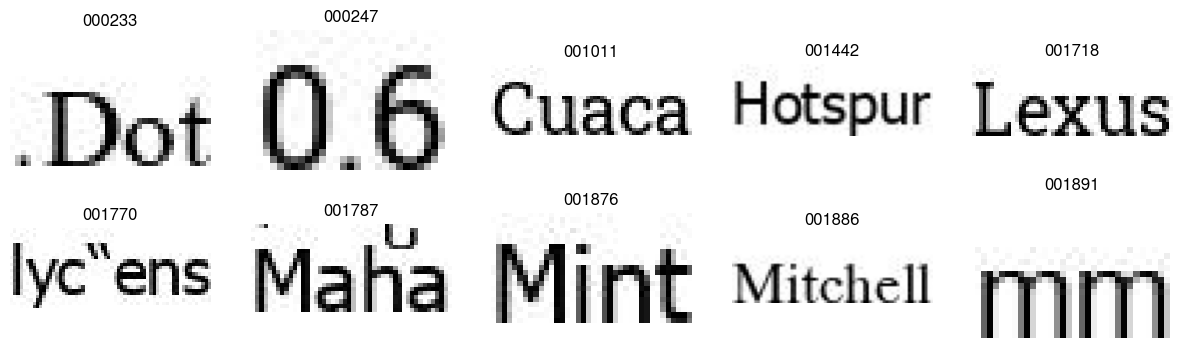

In [5]:
import matplotlib.pyplot as plt
import os

def visualize(dataset_path):
    plt.figure(figsize=(15, 4))
    for i in range(10):
        plt.subplot(2, 5, i+1)
        all_images = os.listdir(f"{dataset_path}/data_train")
        image = plt.imread(f"{dataset_path}/data_train/{all_images[i]}")
        plt.imshow(image)
        plt.axis('off')
        # Setting Khmer font
        plt.rcParams['font.family'] = 'Khmer OS'
        plt.title(all_images[i].split('.')[0], fontname='Khmer OS')
    plt.show()

visualize(DatasetConfig.DATA_ROOT)


## Prepare Dataset

In [6]:
train_df = pd.read_fwf(
    os.path.join(DatasetConfig.DATA_ROOT, 'data_train.txt'), header=None
)
train_df.rename(columns={0: 'file_name', 1: 'text'}, inplace=True)
test_df = pd.read_fwf(
    os.path.join(DatasetConfig.DATA_ROOT, 'data_test.txt'), header=None
)
test_df.rename(columns={0: 'file_name', 1: 'text'}, inplace=True)

In [ ]:
# train_df = pd.read_fwf(os.path.join(DatasetConfig.DATA_ROOT, 'data_train.txt'), header=None)
# train_df.rename(columns={0: 'file_name', 1: 'text'}, inplace=True)

# train_df.head()

In [7]:
train_df.head()

,file_name,text
0,000000.jpg,!(ម៉ានីល
1,000001.jpg,#១
2,000002.jpg,#២
3,000003.jpg,#៥
4,000004.jpg,$109


In [8]:
test_df.head()

,file_name,text
0,022567.jpg,!!!កាលបើ
1,022568.jpg,!Google
2,022569.jpg,$388
3,022570.jpg,$599
4,022571.jpg,(15)


In [ ]:
# Augmentations.
# train_transforms = transforms.Compose([
#     transforms.ColorJitter(brightness=.5, hue=.3),
#     transforms.GaussianBlur(kernel_size=(5, 9), sigma=(0.1, 5)),
# ])

In [87]:
# class CustomOCRDataset(Dataset):
#     def __init__(self, root_dir, df, processor, max_target_length=128):
#         self.root_dir = root_dir
#         self.df = df
#         self.processor = processor
#         self.max_target_length = max_target_length

#     def __len__(self):
#         return len(self.df)

#     def __getitem__(self, idx):
#         # The image file name.
#         file_name = self.df['file_name'][idx]
#         # The text (label).
#         text = self.df['text'][idx]
#         # Read the image, apply augmentations, and get the transformed pixels.
#         image = Image.open(self.root_dir + file_name).convert('RGB')
#         # image = train_transforms(image)
#         pixel_values = self.processor.feature_extractor(image, return_tensors='pt').pixel_values
#         # Pass the text through the tokenizer and get the labels,
#         # i.e. tokenized labels.
#         labels = self.processor.tokenizer(
#             text,
#             padding='max_length',
#             max_length=self.max_target_length
#         ).input_ids
#         # We are using -100 as the padding token.
#         labels = [label if label != self.processor.tokenizer.pad_token_id else -100 for label in labels]
#         encoding = {"pixel_values": pixel_values.squeeze(), "labels": torch.tensor(labels)}
#         return encoding

In [9]:
class CustomOCRDataset(Dataset):
    def __init__(self, root_dir, df, processor, max_target_length=128):
        self.root_dir = root_dir
        self.df = df
        self.processor = processor
        self.max_target_length = max_target_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # The image file name.
        file_name = self.df['file_name'][idx]
        # The text (label).
        text = self.df['text'][idx]
        # Read the image, apply augmentations, and get the transformed pixels.
        image = Image.open(self.root_dir + file_name).convert('RGB')
        # image = train_transforms(image)
        pixel_values = self.processor(image, return_tensors='pt').pixel_values
        # Pass the text through the tokenizer and get the labels,
        # i.e. tokenized labels.
        labels = self.processor.tokenizer(
            text,
            padding='max_length',
            max_length=self.max_target_length
        ).input_ids
        # We are using -100 as the padding token.
        labels = [label if label != self.processor.tokenizer.pad_token_id else -100 for label in labels]
        encoding = {"pixel_values": pixel_values.squeeze(), "labels": torch.tensor(labels)}
        return encoding

In [10]:
# tokenizer = BertTokenizer.from_pretrained("bert-base-multilingual-cased", vocab_file="pretrained_model/bert_module_khmer/assets/vocab_file_BERT_.txt")
# tokenizer = NllbTokenizer.from_pretrained("facebook/nllb-200-distilled-600M") # my modified code
from transformers import ViTFeatureExtractor, AutoTokenizer,XLMRobertaTokenizer,AutoModel
# Load model directly
# tokenizer = XLMRobertaTokenizer.from_pretrained("khmer_trocr_tokenizer")
# Load model directly
# Load model directly
# from transformers import AutoTokenizer, AutoModel

tokenizer = AutoTokenizer.from_pretrained("channudam/khmer-trocr-base-printed")
# model = AutoModel.from_pretrained("channudam/khmer-trocr-base-printed")


# tokenizer = AutoTokenizer.from_pretrained("FacebookAI/xlm-roberta-large")
# model = AutoModelForMaskedLM.from_pretrained("FacebookAI/xlm-roberta-large")
# feature_extractor = ViTFeatureExtractor.from_pretrained(ModelConfig.MODEL_NAME)
# tokenizer = BertTokenizer.from_pretrained("bert-base-multilingual-cased")
feature_extractor = ViTFeatureExtractor.from_pretrained(ModelConfig.MODEL_NAME)

processor = TrOCRProcessor(feature_extractor=feature_extractor, tokenizer=tokenizer)
# processor = TrOCRProcessor.from_pretrained(ModelConfig.MODEL_NAME)
train_dataset = CustomOCRDataset(
    root_dir=os.path.join(DatasetConfig.DATA_ROOT, 'data_train/'),
    df=train_df,
    processor=processor
)
valid_dataset = CustomOCRDataset(
    root_dir=os.path.join(DatasetConfig.DATA_ROOT, 'data_test/'),
    df=test_df,
    processor=processor
)

/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/transformers/models/vit/feature_extraction_vit.py:28: FutureWarning: The class ViTFeatureExtractor is deprecated and will be removed in version 5 of Transformers. Please use ViTImageProcessor instead.
  warnings.warn(
/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/transformers/models/trocr/processing_trocr.py:46: FutureWarning: The `feature_extractor` argument is deprecated and will be removed in v5, use `image_processor` instead.
  warnings.warn(


In [ ]:
# from transformers import BertTokenizer

# # Initialize a Khmer tokenizer (e.g., BERT-based)
# tokenizer = BertTokenizer.from_pretrained("aubmindlab/khbert-base")

# # Khmer text to tokenize
# khmer_text = "សុខ ពិសី លាភ"

# # Tokenize Khmer text
# tokenized_text = tokenizer.encode(khmer_text)

# # Decode tokenized sequence
# decoded_text = tokenizer.decode(tokenized_text)

# print("Tokenized text:", tokenized_text)
# print("Decoded text:", decoded_text)


In [15]:
id =processor.tokenizer.tokenize('ខ្ញុំ')
print(id)

['▁ខ្ញុំ']


In [13]:
encode = processor.tokenizer.add_tokens(['ខ្ញុំ'])
print (encode)

1


In [11]:
id = processor.tokenizer.encode('បង')

print("id: ", id)

id:  [0, 6, 51197, 2]


In [12]:
decode = processor.tokenizer.decode(id) 
print("decode:",decode )

decode: <s> បង</s>


In [14]:
print("Number of training examples:", len(train_dataset))
print("Number of validation examples:", len(valid_dataset))

Number of training examples: 22567
Number of validation examples: 5640


In [11]:
encoding = train_dataset[0]
for k,v in encoding.items():
    print(k, v.shape)

pixel_values torch.Size([3, 384, 384])
labels torch.Size([128])


(-0.5, 75.5, 25.5, -0.5)

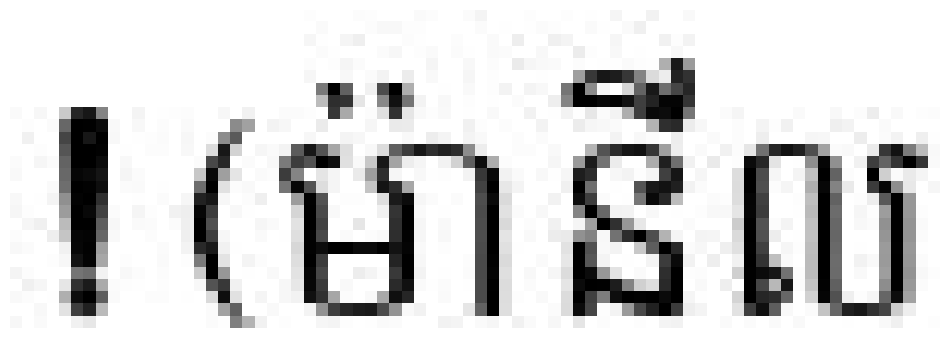

In [10]:
image = Image.open(train_dataset.root_dir + train_df['file_name'][0]).convert("RGB")
# image = train_transforms(image)
plt.imshow(image)
plt.axis('off')

In [12]:
labels = encoding['labels']
labels[labels == -100] = processor.tokenizer.pad_token_id
label_str = processor.decode(labels, skip_special_tokens=True)
print(label_str)

!(ម៉ានីល


In [92]:
# labels = encoding['labels']

# # Replace -100 with pad token id
# labels[labels == -100] = processor.tokenizer.pad_token_id

# # Decode labels
# label_str = processor.tokenizer.decode(labels, skip_special_tokens=True)

# print(label_str)


ម៉ានីល


In [13]:
# Check the tokenizer vocabulary size
vocab_size = processor.tokenizer.vocab_size
print(f"Tokenizer vocabulary size: {vocab_size}")

Tokenizer vocabulary size: 250002


In [ ]:
# Example usage assuming `df` is your DataFrame and `processor` is your processor object
# Initialize dataset
dataset = CustomOCRDataset(root_dir='dataset/data_train/', df=train_df, processor=processor, max_target_length=32)

# Example: Print label IDs for the first example in the dataset
print(dataset[1000])


In [21]:
from transformers import NllbTokenizer

# Example token IDs (replace with actual token IDs from your dataset)
token_ids = [  256047,  19947,  32063,      2,   -100,   -100,   -100]

# Load the tokenizer used in your CustomOCRDataset
# tokenizer = AutoTokenizer.from_pretrained("khmer_tokenizer")
# tokenizer = AutoTokenizer.from_pretrained("GKLMIP/bert-khmer-small-uncased-tokenized")

# Ensure all token IDs are valid
valid_token_ids = [tid for tid in token_ids if tid != -100]

# Decode token IDs to text
decoded_text = processor.batch_decode(valid_token_ids, skip_special_tokens=True)

print("Decoded Text:", decoded_text)


Decoded Text: ['', 'aantal', 'maisha', '']


## Initialize the Model

In [14]:
# model = VisionEncoderDecoderModel.from_pretrained("kkatiz/thai-trocr-thaigov-v2")
model = VisionEncoderDecoderModel.from_pretrained(ModelConfig.MODEL_NAME)

model.to(device)
print(model)
# Total parameters and trainable parameters.
total_params = sum(p.numel() for p in model.parameters())
print(f"{total_params:,} total parameters.")
total_trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad)
print(f"{total_trainable_params:,} training parameters.")

Some weights of VisionEncoderDecoderModel were not initialized from the model checkpoint at microsoft/trocr-small-printed and are newly initialized: ['encoder.pooler.dense.bias', 'encoder.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


VisionEncoderDecoderModel(
  (encoder): DeiTModel(
    (embeddings): DeiTEmbeddings(
      (patch_embeddings): DeiTPatchEmbeddings(
        (projection): Conv2d(3, 384, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): DeiTEncoder(
      (layer): ModuleList(
        (0-11): 12 x DeiTLayer(
          (attention): DeiTAttention(
            (attention): DeiTSelfAttention(
              (query): Linear(in_features=384, out_features=384, bias=True)
              (key): Linear(in_features=384, out_features=384, bias=True)
              (value): Linear(in_features=384, out_features=384, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (output): DeiTSelfOutput(
              (dense): Linear(in_features=384, out_features=384, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (intermediate): DeiTIntermediate(
            (dense): Linear(

In [15]:
# Resize token embeddings if necessary
model.decoder.resize_token_embeddings(len(tokenizer))

Embedding(250002, 256)

In [14]:
print(model.config)

VisionEncoderDecoderConfig {
  "_name_or_path": "channudam/khmer-trocr-base-printed",
  "architectures": [
    "VisionEncoderDecoderModel"
  ],
  "decoder": {
    "_name_or_path": "channudam/khmer-xlm-roberta-base",
    "add_cross_attention": true,
    "architectures": [
      "XLMRobertaForMaskedLM"
    ],
    "attention_probs_dropout_prob": 0.1,
    "bad_words_ids": null,
    "begin_suppress_tokens": null,
    "bos_token_id": 0,
    "chunk_size_feed_forward": 0,
    "classifier_dropout": null,
    "cross_attention_hidden_size": null,
    "decoder_start_token_id": null,
    "diversity_penalty": 0.0,
    "do_sample": false,
    "early_stopping": false,
    "encoder_no_repeat_ngram_size": 0,
    "eos_token_id": 2,
    "exponential_decay_length_penalty": null,
    "finetuning_task": null,
    "forced_bos_token_id": null,
    "forced_eos_token_id": null,
    "hidden_act": "gelu",
    "hidden_dropout_prob": 0.1,
    "hidden_size": 768,
    "id2label": {
      "0": "LABEL_0",
      "1": "LA

## Model Configurations

In [16]:
# Set special tokens used for creating the decoder_input_ids from the labels.
model.config.decoder_start_token_id = processor.tokenizer.cls_token_id
model.config.pad_token_id = processor.tokenizer.pad_token_id
# Set Correct vocab size.
model.config.vocab_size = model.config.decoder.vocab_size
model.config.eos_token_id = processor.tokenizer.sep_token_id

# model.config.max_length = 64
# model.config.early_stopping = True
# model.config.no_repeat_ngram_size = 3
# model.config.length_penalty = 2.0
# model.config.num_beams = 4

We use the AdamW optimizer here with a weight decay of 0.0005.

In [17]:
optimizer = optim.AdamW(
    model.parameters(), lr=TrainingConfig.LEARNING_RATE, weight_decay=0.0005
)

## Evaluation Metric

In [18]:
cer_metric = evaluate.load('cer')

In [18]:
# def compute_cer(pred):
#     labels_ids = pred.label_ids
#     pred_ids = pred.predictions

#     pred_str = processor.batch_decode(pred_ids, skip_special_tokens=True)
#     labels_ids[labels_ids == -100] = processor.tokenizer.pad_token_id
#     label_str = processor.batch_decode(labels_ids, skip_special_tokens=True)

#     cer = cer_metric.compute(predictions=pred_str, references=label_str)

#     return {"cer": cer}

In [19]:
def compute_cer(pred):
    labels_ids = pred.label_ids
    pred_ids = pred.predictions

    # Decode the predictions and labels
    pred_str = processor.batch_decode(pred_ids, skip_special_tokens=True)
    labels_ids[labels_ids == -100] = processor.tokenizer.pad_token_id
    label_str = processor.batch_decode(labels_ids, skip_special_tokens=True)

    # Check for empty strings in predictions and labels
    empty_label_indices = [i for i, l in enumerate(label_str) if not l]

    if empty_label_indices:
        print(f"Empty labels found at indices: {empty_label_indices}")

    # Filter out empty labels and corresponding predictions
    filtered_pred_str = [p for i, p in enumerate(pred_str) if i not in empty_label_indices]
    filtered_label_str = [l for l in label_str if l]

    # Ensure that the lengths of predictions and labels match after filtering
    if len(filtered_pred_str) != len(filtered_label_str):
        raise ValueError("Mismatch between number of predictions and labels after removing empty strings.")

    # Compute CER
    cer = cer_metric.compute(predictions=filtered_pred_str, references=filtered_label_str)

    return {"cer": cer}


## Training and Validation Loops

In [20]:
training_args = Seq2SeqTrainingArguments(
    predict_with_generate=True,
    evaluation_strategy='epoch',
    per_device_train_batch_size=TrainingConfig.BATCH_SIZE,
    per_device_eval_batch_size=TrainingConfig.BATCH_SIZE,
    fp16=False,
    output_dir='channudam/',
    logging_strategy='epoch',
    save_strategy='epoch',
    save_total_limit=5,
    report_to='tensorboard',
    num_train_epochs=TrainingConfig.EPOCHS
)

/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/transformers/training_args.py:1474: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


In [21]:
# Initialize trainer.
trainer = Seq2SeqTrainer(
    model=model,
    tokenizer=processor.tokenizer,
    args=training_args,
    compute_metrics=compute_cer,
    train_dataset=train_dataset,
    eval_dataset=valid_dataset,
    data_collator=default_data_collator
)

## Train

In [26]:
res = trainer.train()

/home/EmHengly/.local/lib/python3.10/site-packages/torch/nn/parallel/_functions.py:68: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn('Was asked to gather along dimension 0, but all '


Epoch,Training Loss,Validation Loss,Cer
1,4.606200,3.766934,0.916846
2,3.415000,3.171812,1.156679
3,2.801600,2.672153,0.866339
4,2.289400,2.249367,0.719857
5,1.852700,1.898575,0.659064
6,1.506400,1.669582,0.578056
7,1.211500,1.485721,0.532081
8,0.986700,1.355084,0.512701
9,0.788600,1.236073,0.387835
10,0.640800,1.137661,0.381366


/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/transformers/generation/utils.py:1168: UserWarning: Using the model-agnostic default `max_length` (=20) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(
/home/EmHengly/.local/lib/python3.10/site-packages/torch/nn/parallel/_functions.py:68: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn('Was asked to gather along dimension 0, but all '
/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/transformers/generation/utils.py:1168: UserWarning: Using the model-agnostic default `max_length` (=20) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(
/home/EmHengly/.local/lib/python3.10/site-packages/torch/nn/parallel/_functions.py:68: UserWarning:

In [1]:
res

NameError: name 'res' is not defined

## Inference

In [35]:
device = torch.device('cuda:0' if torch.cuda.is_available else 'cpu')

In [22]:
# processor = TrOCRProcessor.from_pretrained(ModelConfig.MODEL_NAME)
# trained_model = VisionEncoderDecoderModel.from_pretrained('ocrmodel-khmer-trocr-tokenizer/checkpoint-'+str(res.global_step)).to(device)
trained_model = VisionEncoderDecoderModel.from_pretrained('channudam/checkpoint-14120').to(device)

In [23]:
def read_and_show(image_path):
    """
    :param image_path: String, path to the input image.

    Returns:
        image: PIL Image.
    """
    image = Image.open(image_path).convert('RGB')
    return image

In [49]:
def ocr(image, processor, model):
    """
    :param image: PIL Image.
    :param processor: Huggingface OCR processor.
    :param model: Huggingface OCR model.

    Returns:
        generated_text: the OCR'd text string.
    """
    # We can directly perform OCR on cropped images.
    pixel_values = processor(image, return_tensors='pt').pixel_values.to(device)
    generated_ids = model.generate(pixel_values)
    generated_text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
    # Encode the generated text to bytes using UTF-8 encoding
    # encoded_text = generated_text.decode('utf-8')
    # return encoded_text
    return generated_text

In [47]:
def eval_new_data(
    data_path=os.path.join(DatasetConfig.DATA_ROOT, 'data_test', '*'),
    num_samples=50
):
    image_paths = glob.glob(data_path)
    # Set a font that supports a wide range of characters
    plt.rcParams['font.family'] = 'Khmer OS'
    for i, image_path in tqdm(enumerate(image_paths), total=len(image_paths)):
        if i == num_samples:
            break
        image = read_and_show(image_path)
        text = ocr(image, processor, trained_model)
        plt.figure(figsize=(7, 4))
        plt.imshow(image)
        plt.title(text)
        plt.axis('off')
        plt.show()
        # print(text)
        
        # Print the generated text
        print("Generated Text:", text)

  0%|          | 0/5640 [00:00<?, ?it/s]

/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/transformers/generation/utils.py:1168: UserWarning: Using the model-agnostic default `max_length` (=20) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


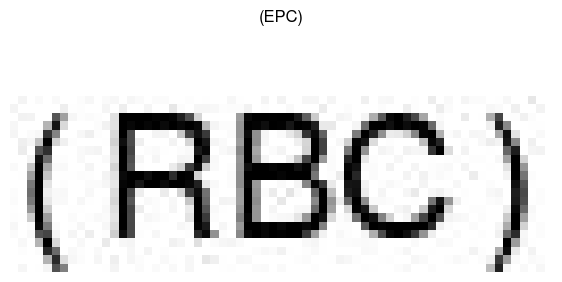

Generated Text: (EPC)


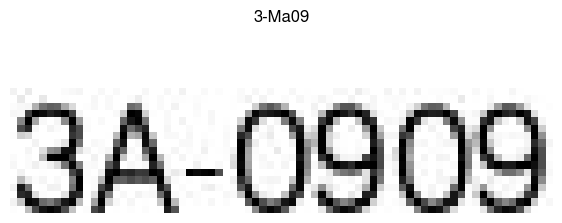

Generated Text: 3-Ma09


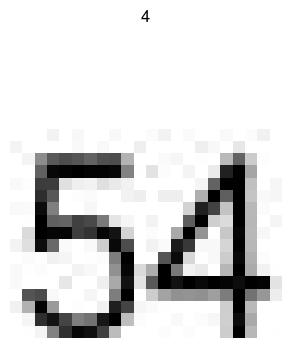

Generated Text: 4


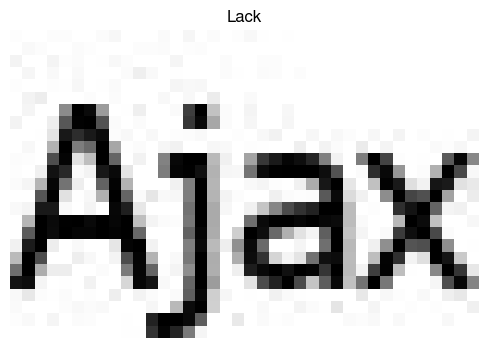

Generated Text: Lack


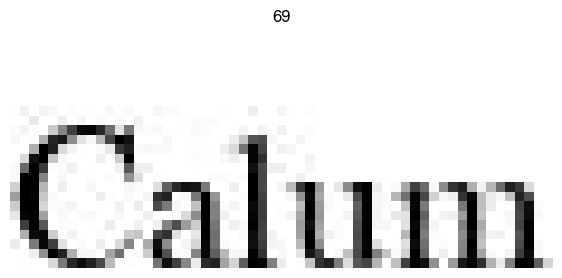

Generated Text: 69


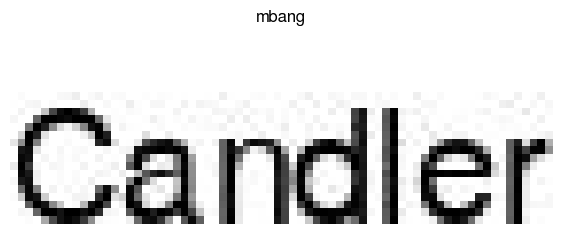

Generated Text: mbang


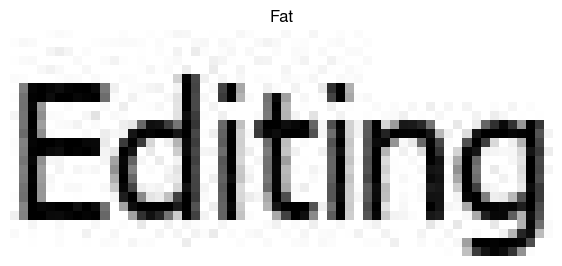

Generated Text: Fat


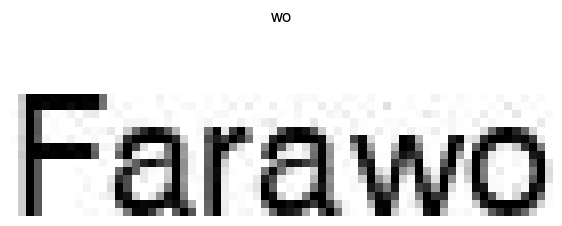

Generated Text: wo


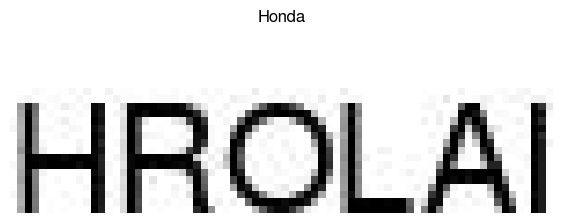

Generated Text: Honda


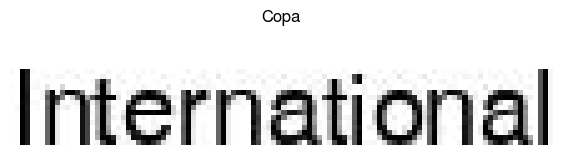

Generated Text: Copa


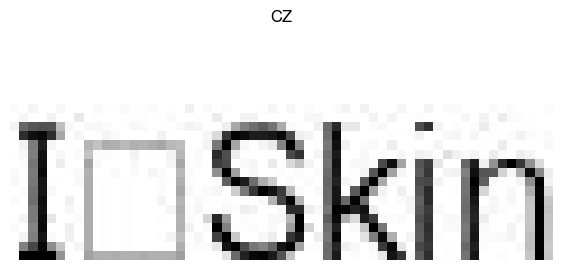

Generated Text: CZ


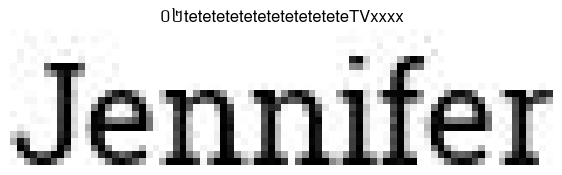

Generated Text: ០២teteteteteteteteteteteteTVxxxx


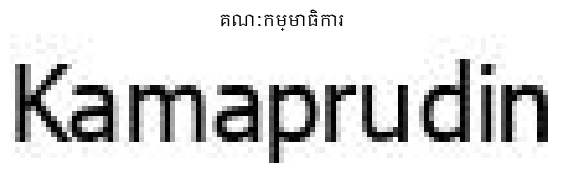

Generated Text: គណៈកម្មាធិការ


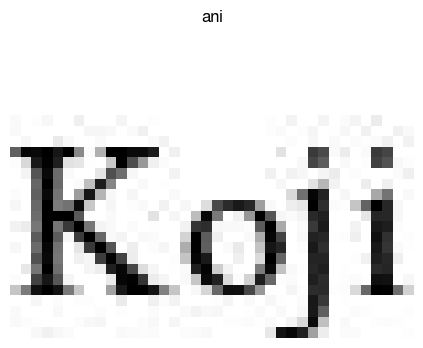

Generated Text: ani


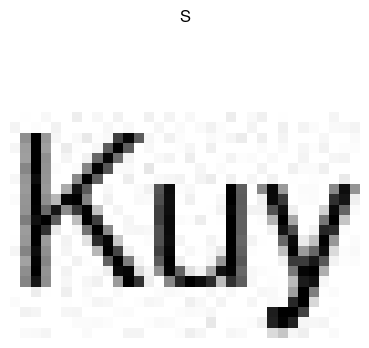

Generated Text: S


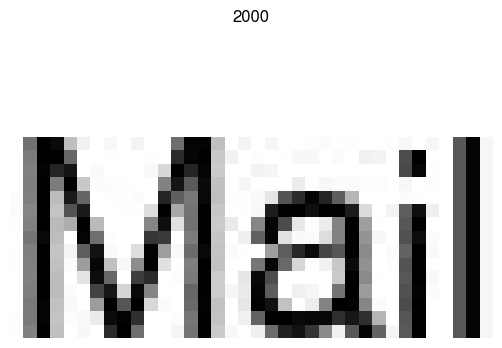

Generated Text: 2000


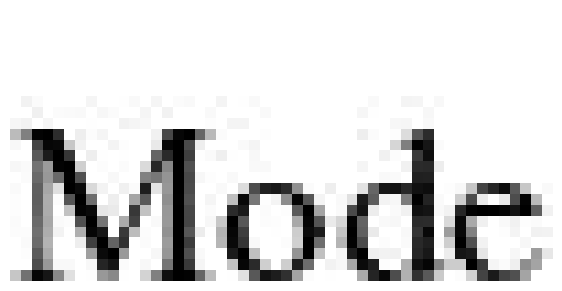

Generated Text: 


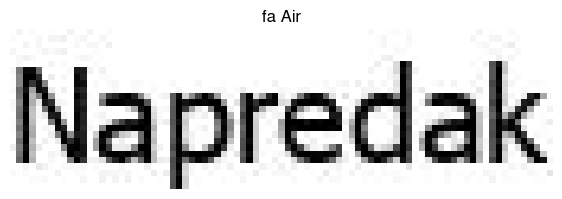

Generated Text: fa Air


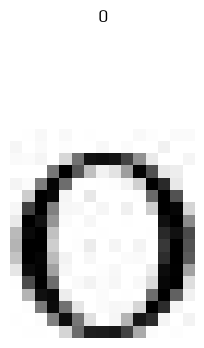

Generated Text: ០


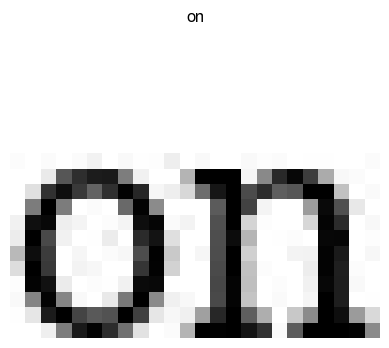

Generated Text: on


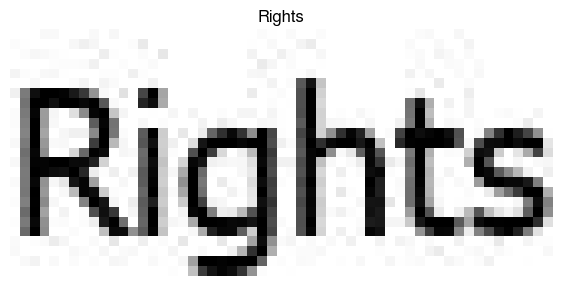

Generated Text: Rights


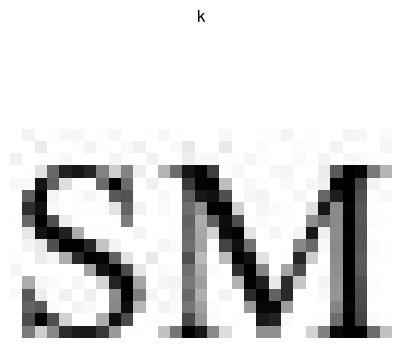

Generated Text: k


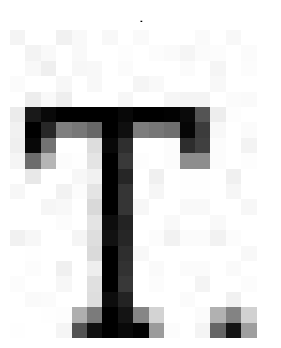

Generated Text: .


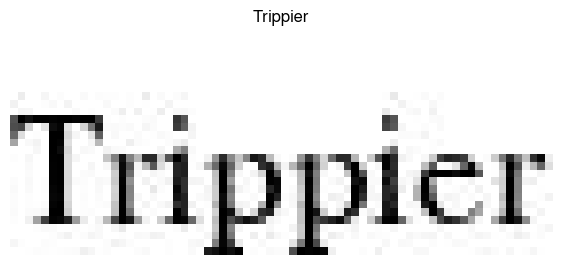

Generated Text: Trippier


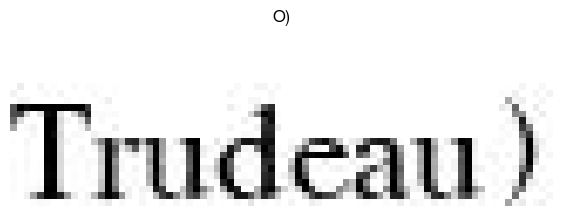

Generated Text: O)


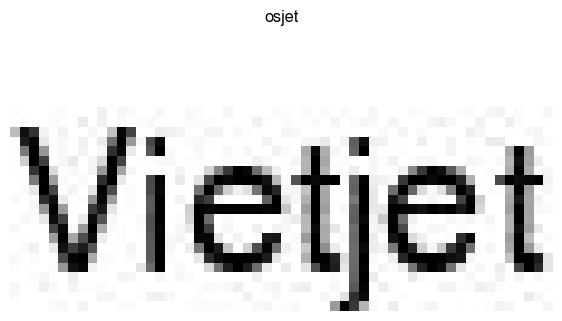

Generated Text: osjet


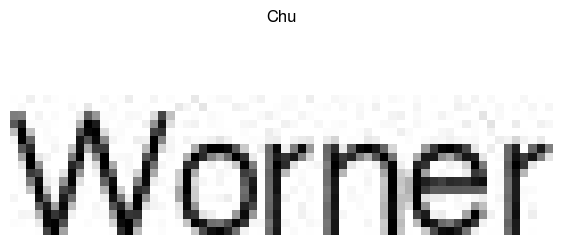

Generated Text: Chu


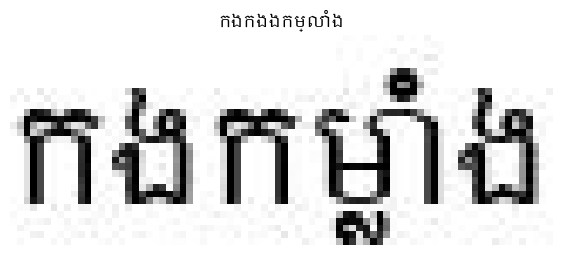

Generated Text: កងកងងកម្លាំង


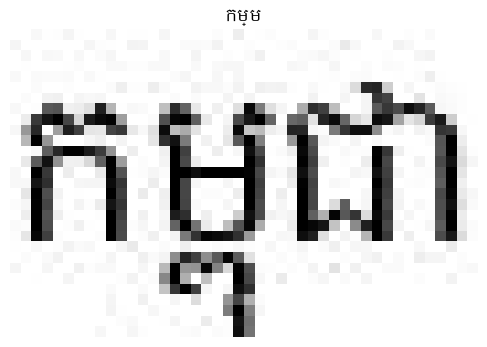

Generated Text: កម្ម


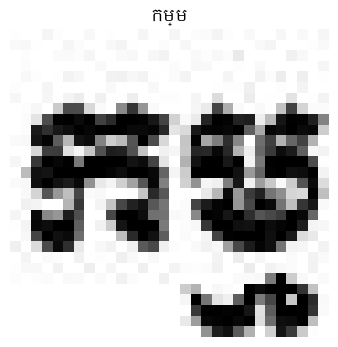

Generated Text: កម្ម


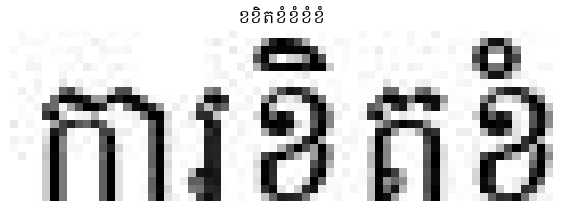

Generated Text: ខខិតខំខំខំខំំំំំំំំំ


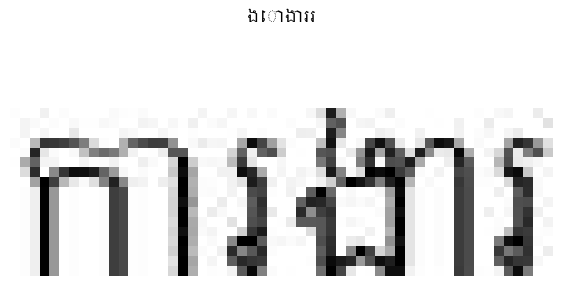

Generated Text: ងោងាររ


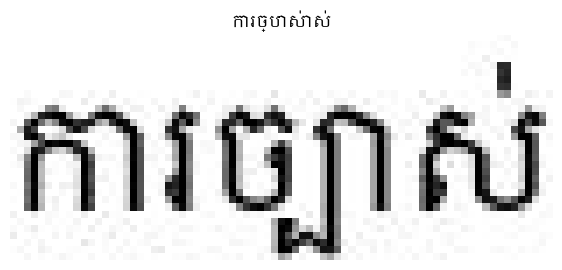

Generated Text: ការច្បាស់ាស់


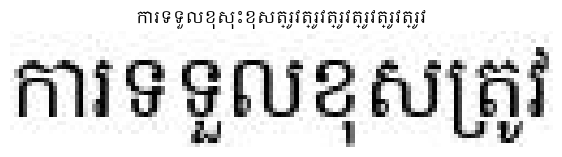

Generated Text: ការទទួលខុសុះខុសត្រូវត្រូវត្រូវត្រូវត្រូវត្រូវ


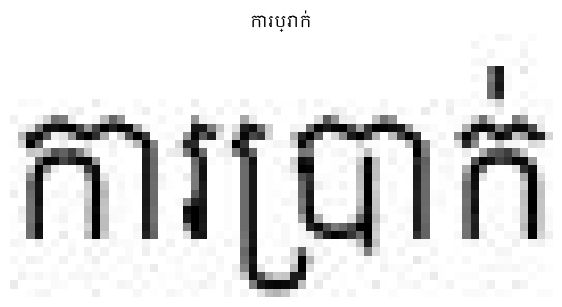

Generated Text: ការប្រាក់


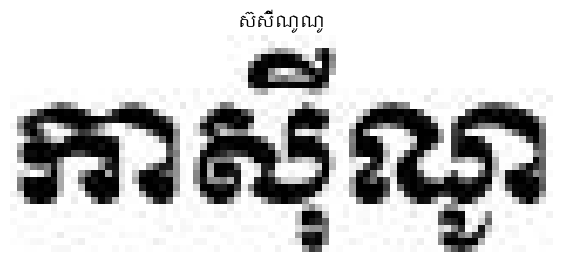

Generated Text: ស៊ស៊ីណូណូូ


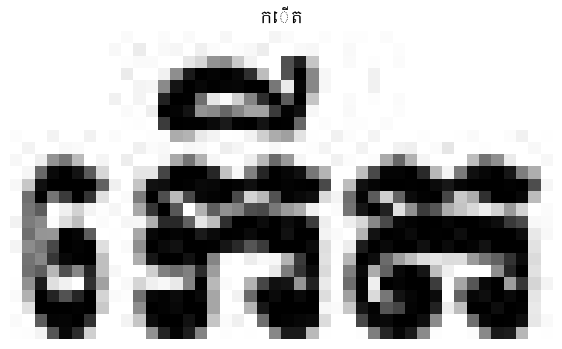

Generated Text: កើត


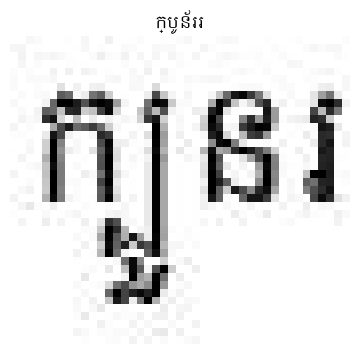

Generated Text: ក្បូន័ររ


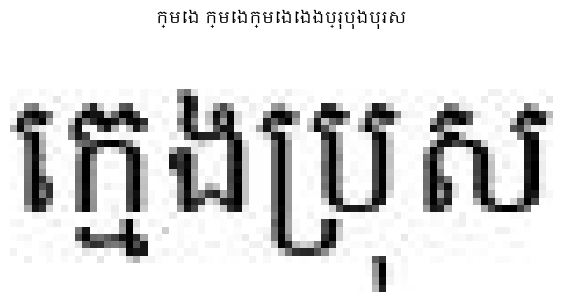

Generated Text: ក្មេង ក្មេងក្មេងេងងប្រុបុងបុរស


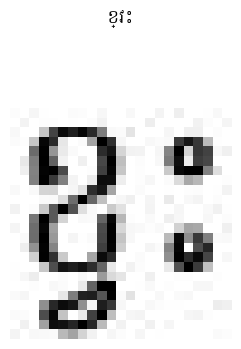

Generated Text: ខ្វះ


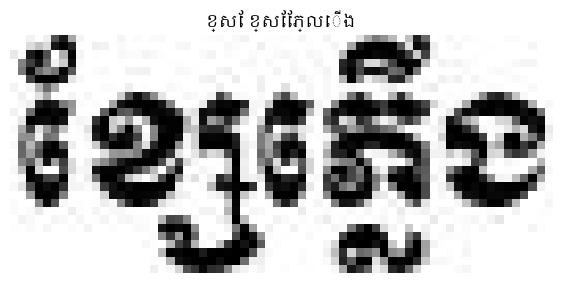

Generated Text: ខ្សែ ខ្សែែភ្លើង


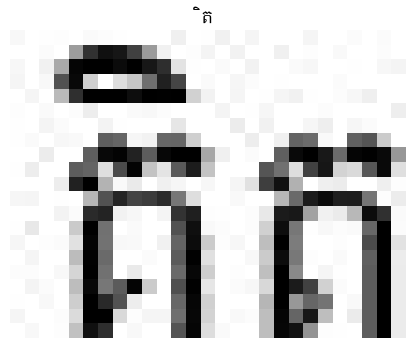

Generated Text: ិត


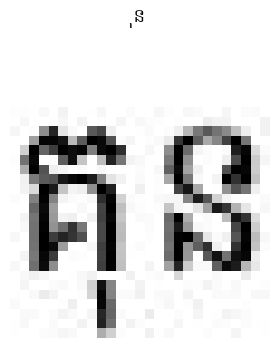

Generated Text: ុន


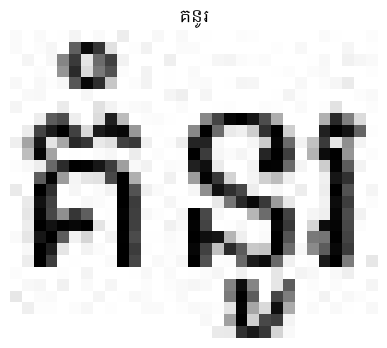

Generated Text: គនូរ


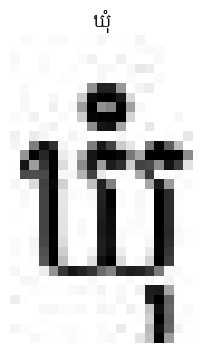

Generated Text: ឃុំ


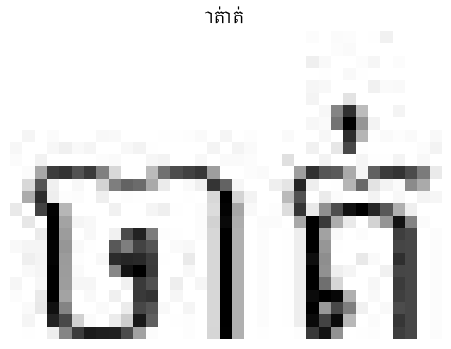

Generated Text: ាត់ាត់


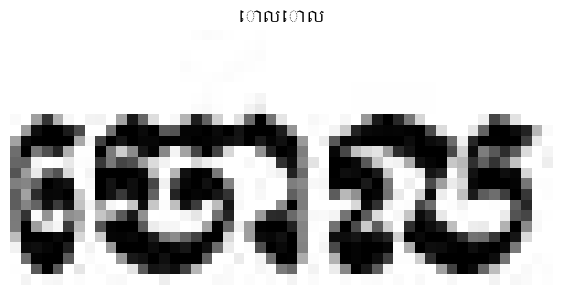

Generated Text: ោលោល


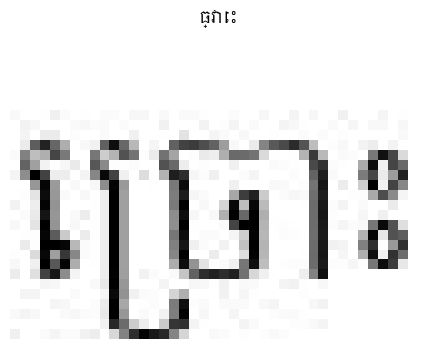

Generated Text: ធ្វាេះ


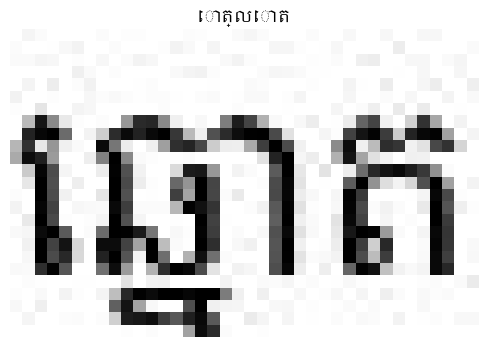

Generated Text: ោត្លោត


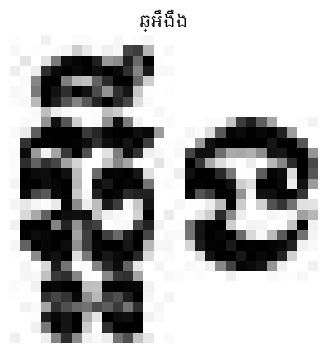

Generated Text: ឆ្អឹងឹង


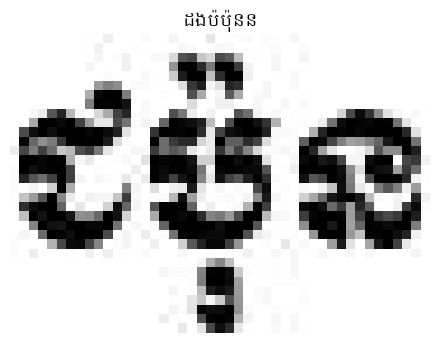

Generated Text: ដងប៉ប៉ុនន


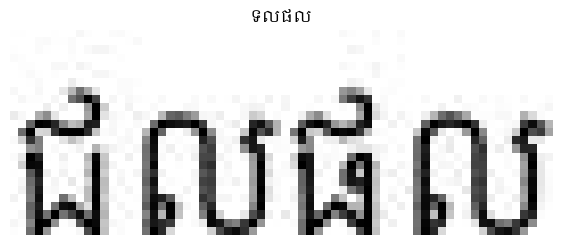

Generated Text: ទលផល


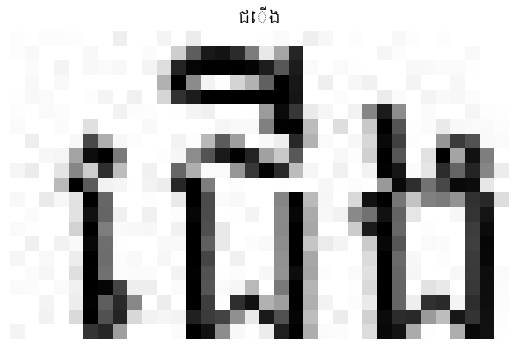

Generated Text: ជើង


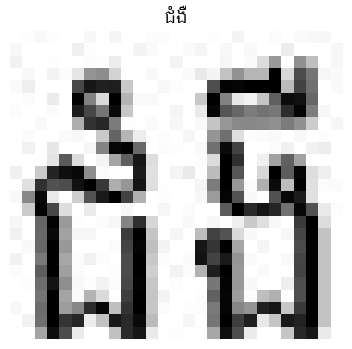

Generated Text: ជំងឺ


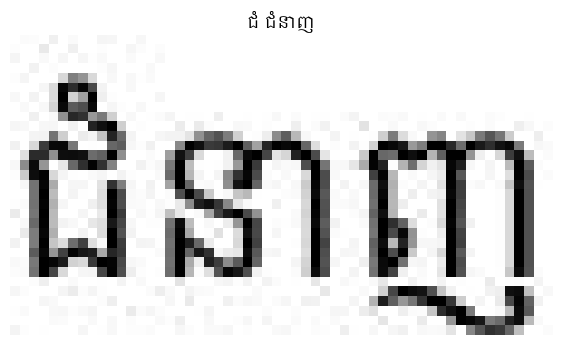

Generated Text: ជំ ជំនាញ


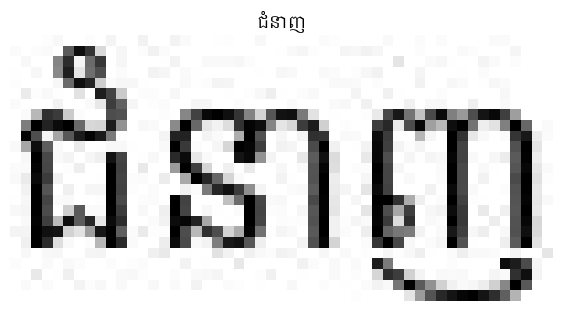

Generated Text: ជំនាញ


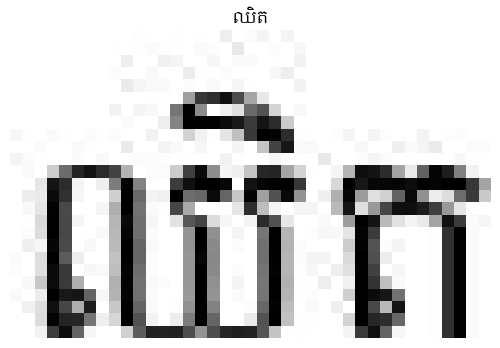

Generated Text: ឈិត


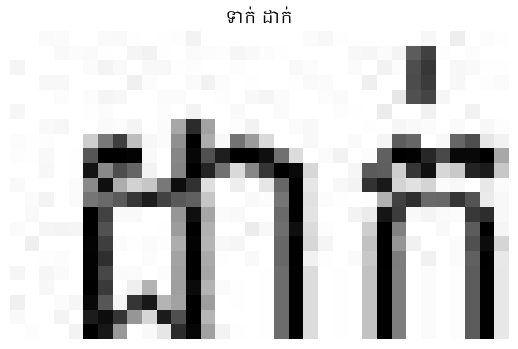

Generated Text: ទាក់ ដាក់


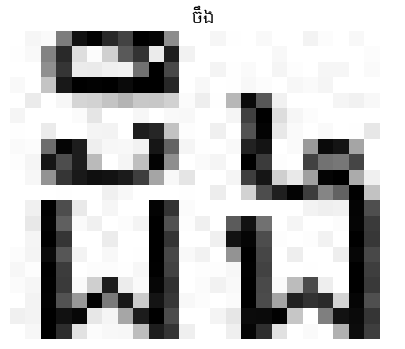

Generated Text: ចឹង


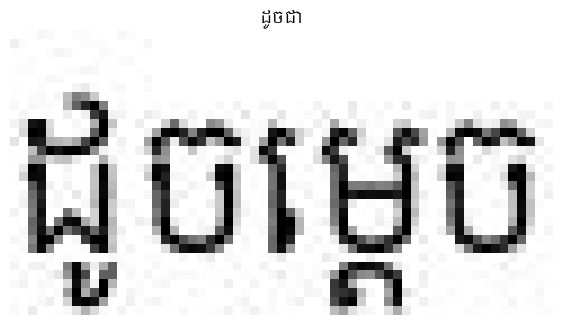

Generated Text: ដូចជា


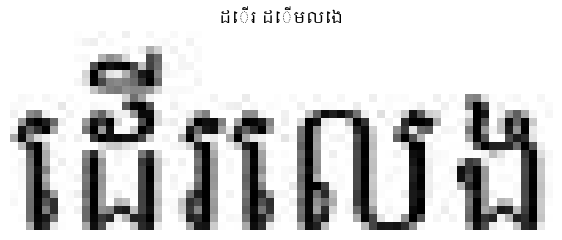

Generated Text: ដើរ ដើមលេង


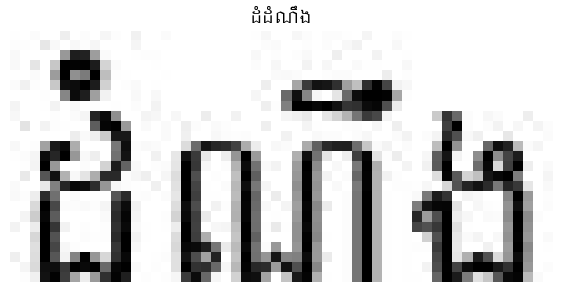

Generated Text: ដំដំណឹង


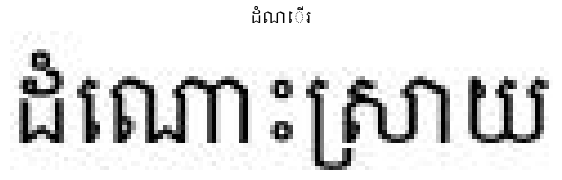

Generated Text: ដំណើរ


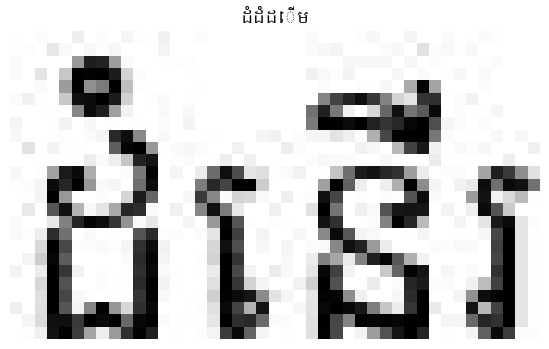

Generated Text: ដំដំដើម


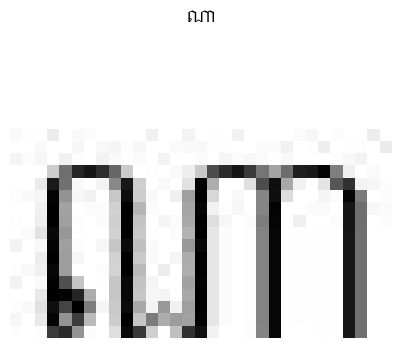

Generated Text: ណា


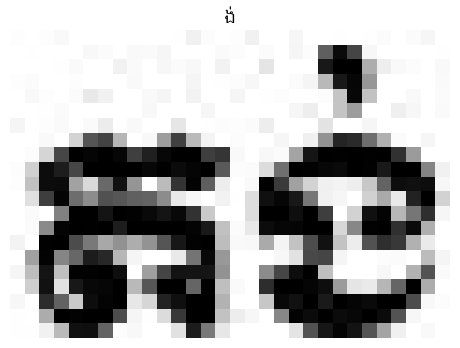

Generated Text: ង់


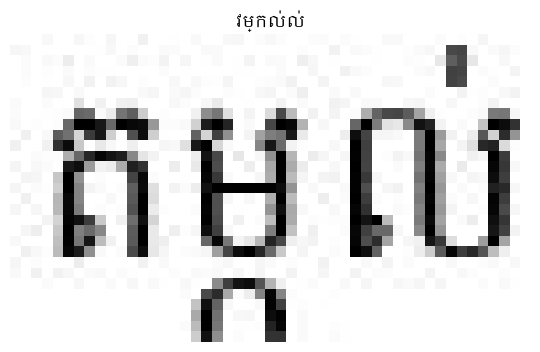

Generated Text: វម្កល់ល់


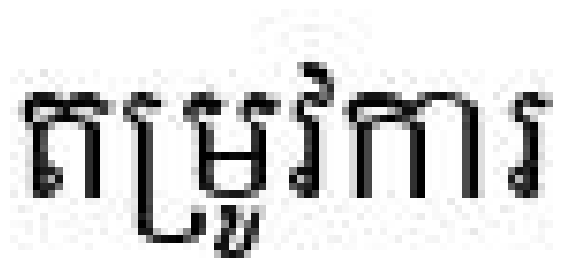

Generated Text: 


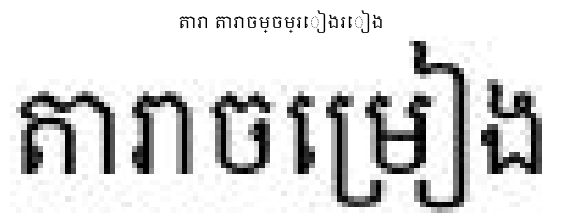

Generated Text: តារា តារាចម្ចម្រៀងរៀង


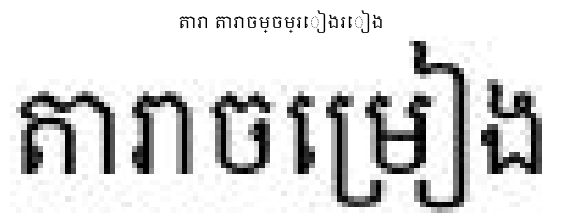

Generated Text: តារា តារាចម្ចម្រៀងរៀង


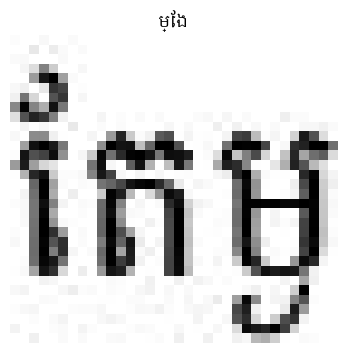

Generated Text: ម្ែង


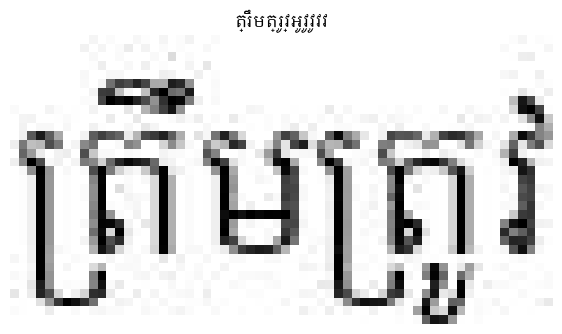

Generated Text: ត្រឹមត្រូវ្អូូវូវូវវ


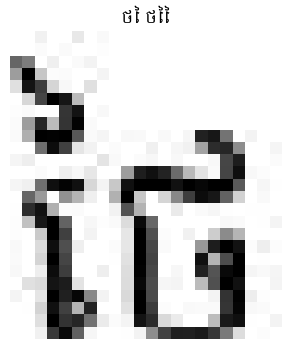

Generated Text: ថៃ ថៃៃ


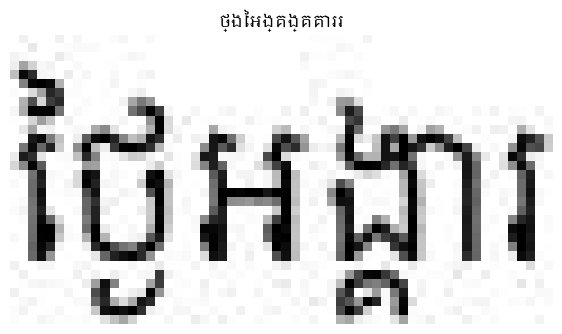

Generated Text: ថ្ងៃអង្គង្គគាររ


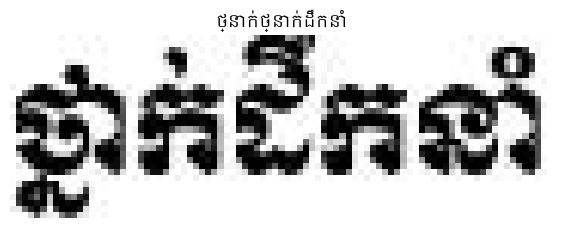

Generated Text: ថ្នាក់ថ្នាក់ដឹកនាំ


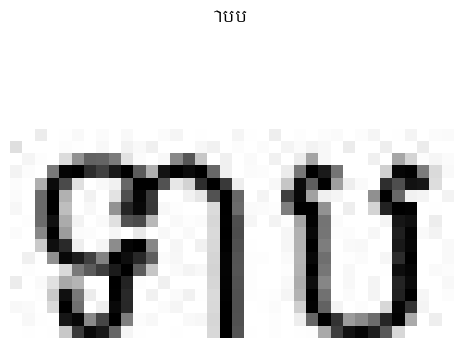

Generated Text: ាបប


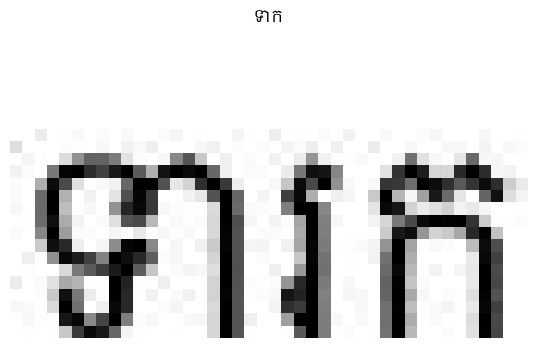

Generated Text: ទាក


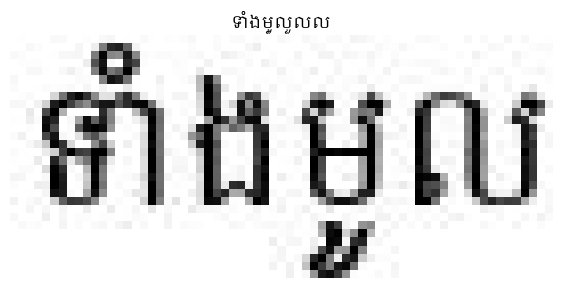

Generated Text: ទាំងម្ួលួលល


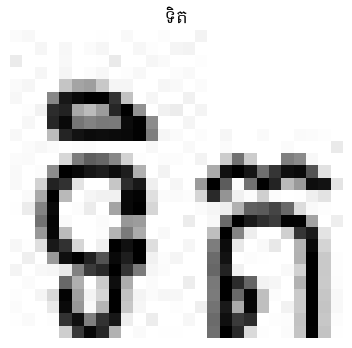

Generated Text: ទិិត


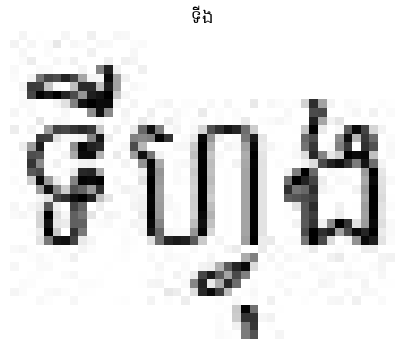

Generated Text: ទីង


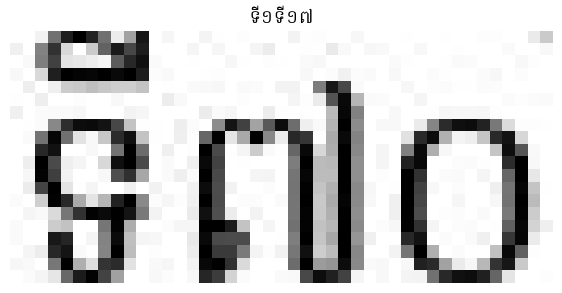

Generated Text: ទី១ទី១៧


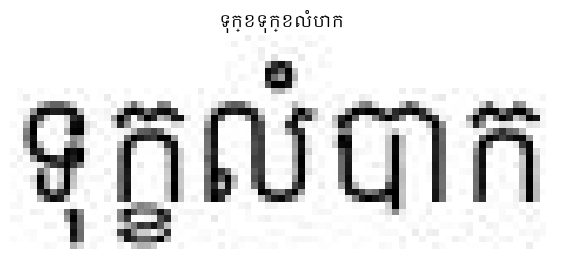

Generated Text: ទុក្ខទុក្ខលំបាក


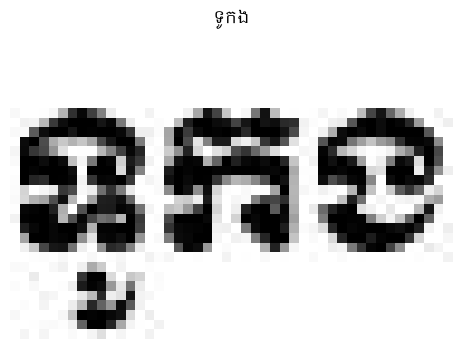

Generated Text: ទូូកង


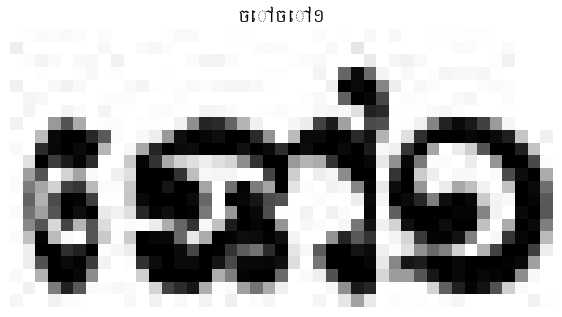

Generated Text: ចៅចៅ១


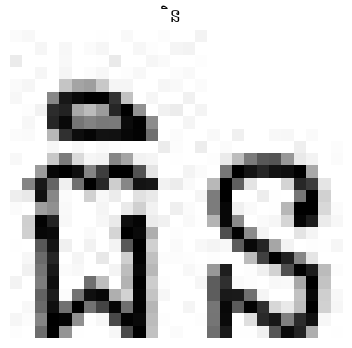

Generated Text: ិន


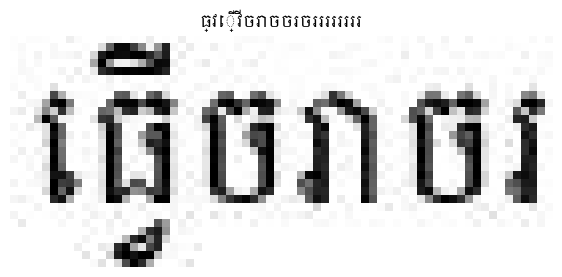

Generated Text: ធ្វើ្វីចរាចចរចររររររររ


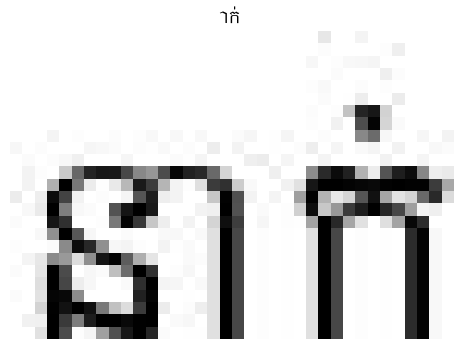

Generated Text: ាក់


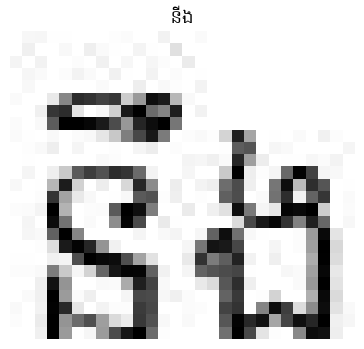

Generated Text: នីង


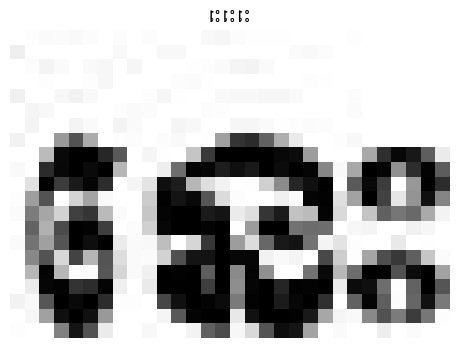

Generated Text: េះេះេះ


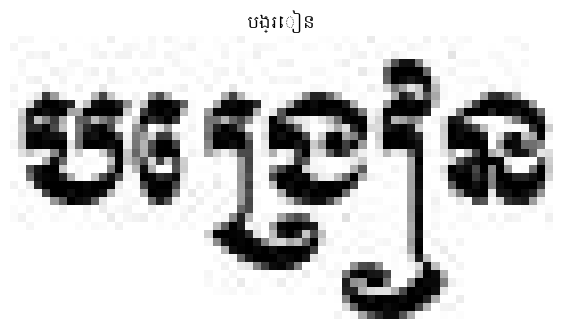

Generated Text: បង្រៀន


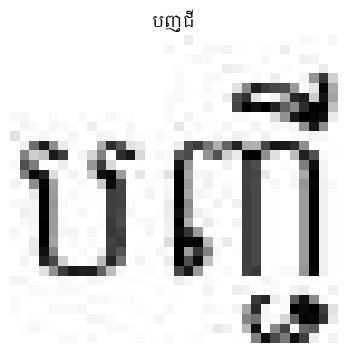

Generated Text: បញ្ជី


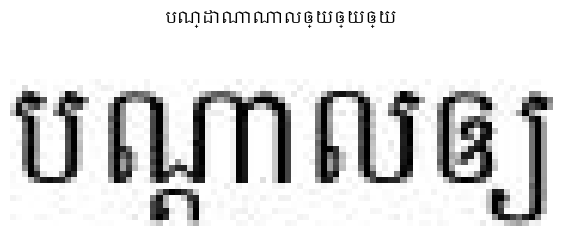

Generated Text: បណ្ដាណាណាលឲ្យឲ្យឲ្យ


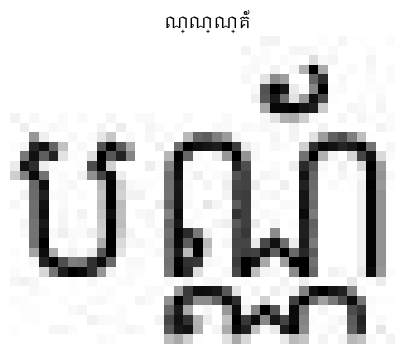

Generated Text: ណ្ណ្ណ្គ័័័ំ


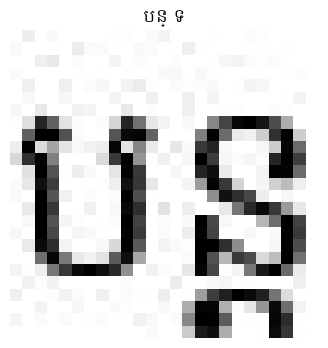

Generated Text: បន្ ទ


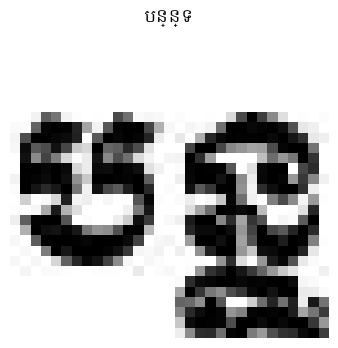

Generated Text: បន្ន្ទ


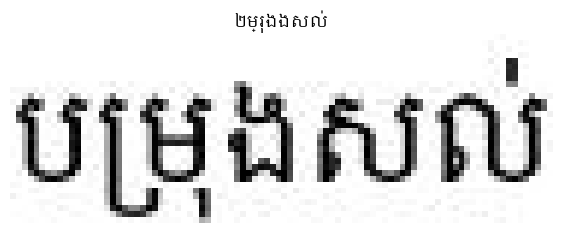

Generated Text: ២ម្រុងងសល់


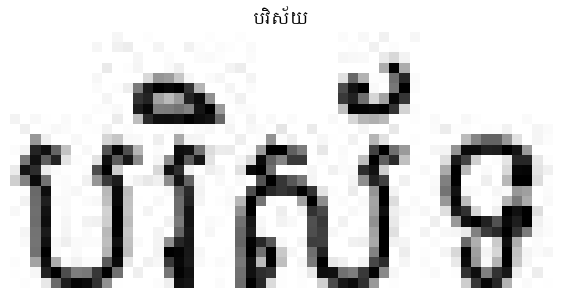

Generated Text: បវិស័យ


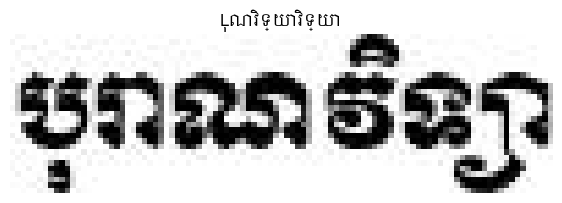

Generated Text: Lុណវិទ្យាវិទ្យា


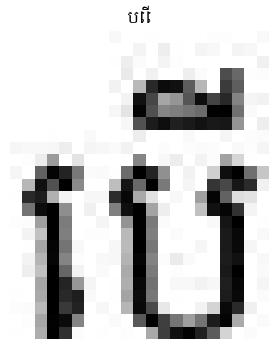

Generated Text: បេេី


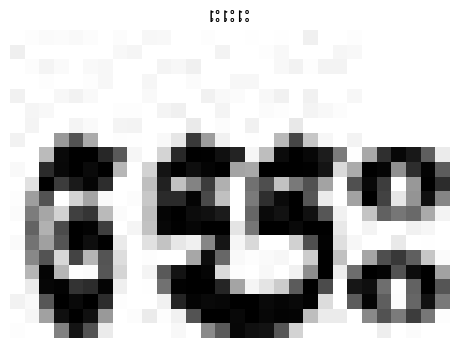

Generated Text: េះេះេះ


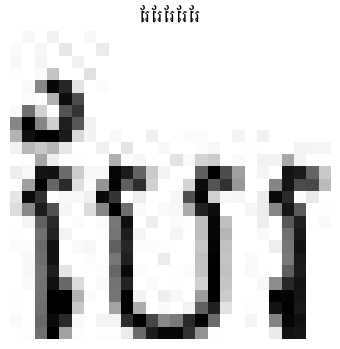

Generated Text: ែរែរែរែរែរ


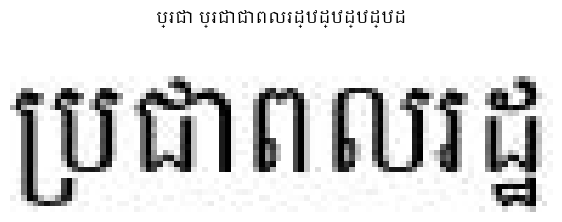

Generated Text: ប្រជា ប្រជាជាពលរដ្ឋដ្ឋដ្ឋដ្ឋដ


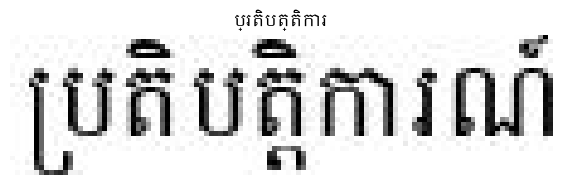

Generated Text: ប្រតិបត្តិការ


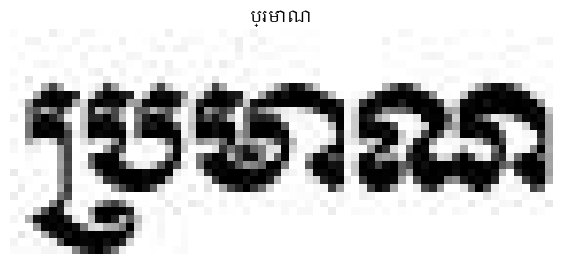

Generated Text: ប្រមាណ


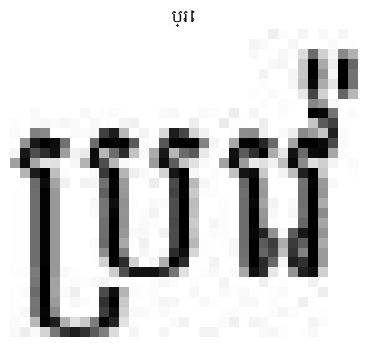

Generated Text: ប្រេ


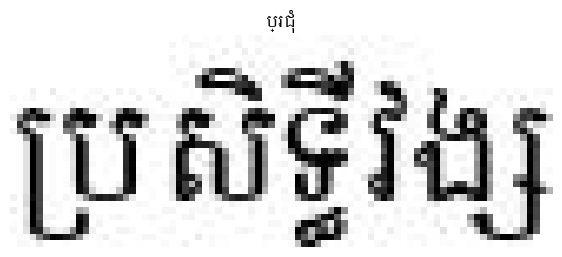

Generated Text: ប្រជុំ


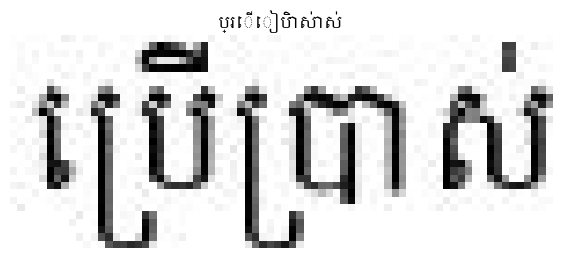

Generated Text: ប្រើៀបិាស់ាស់


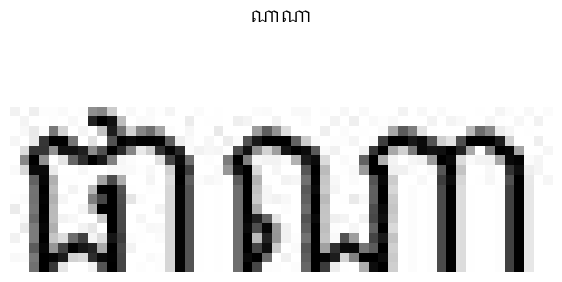

Generated Text: ណាណា


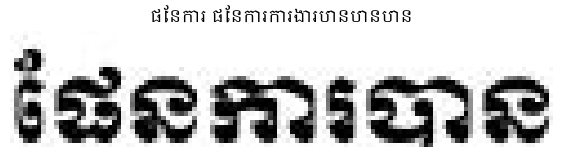

Generated Text: ផែនការ ផែនការការងារបានបានបាន


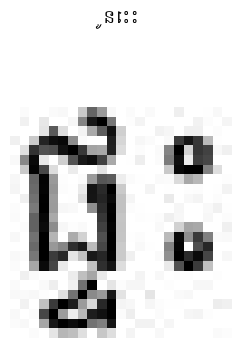

Generated Text: ូនេះះ


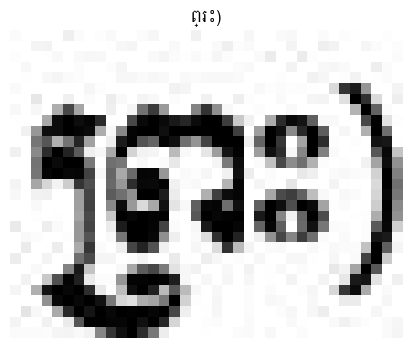

Generated Text: ព្រះ)


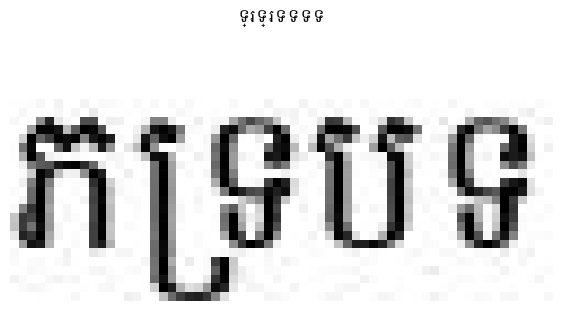

Generated Text: ទ្រទ្រទទទទ


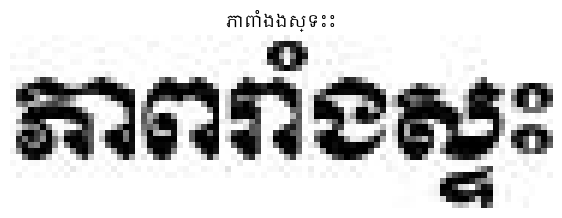

Generated Text: ភាពាំងងស្ទះះ


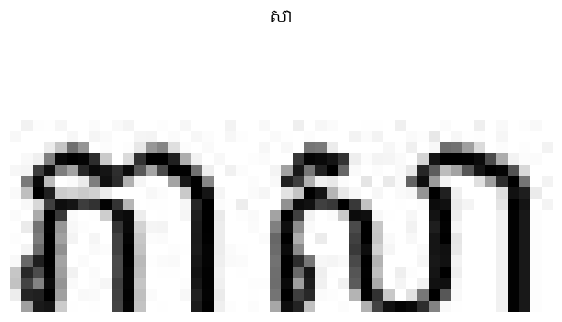

Generated Text: សា


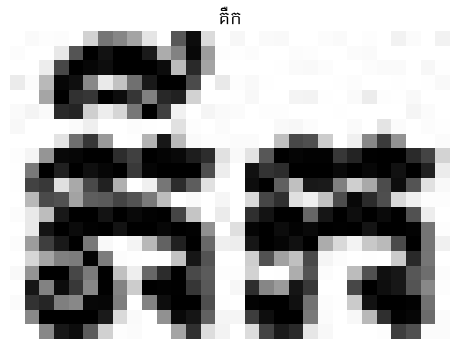

Generated Text: គីឺក


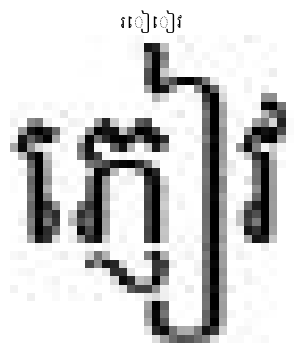

Generated Text: រៀៀវ


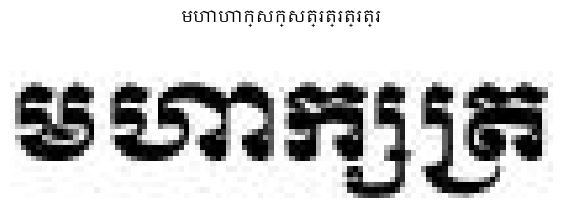

Generated Text: មហាហាក្សក្សត្រត្រត្រត្រ


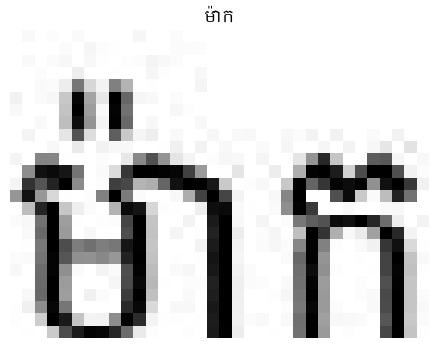

Generated Text: ម៉ាក


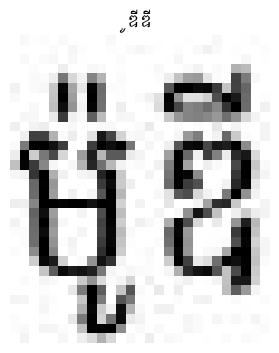

Generated Text: ូឌីឌីី


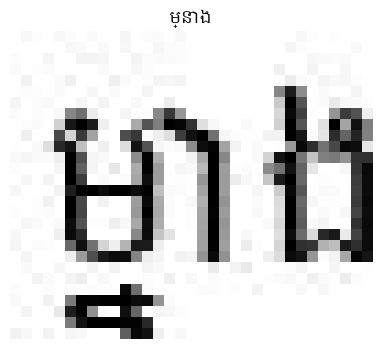

Generated Text: ម្នាង


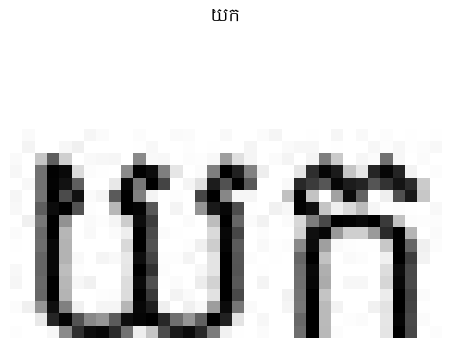

Generated Text: យក


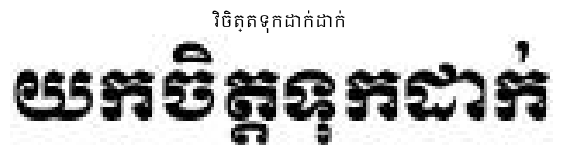

Generated Text: វិចិត្តទុកដាក់ដាក់


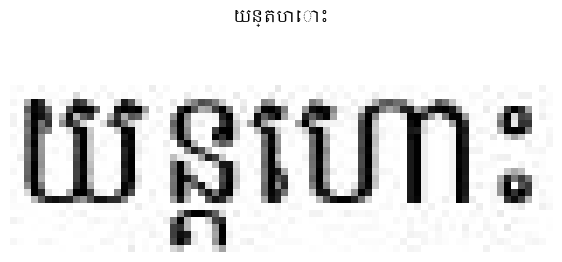

Generated Text: យន្តហោះ


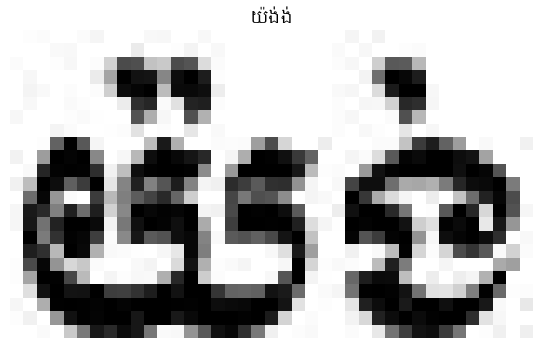

Generated Text: យ៉ង់ង់


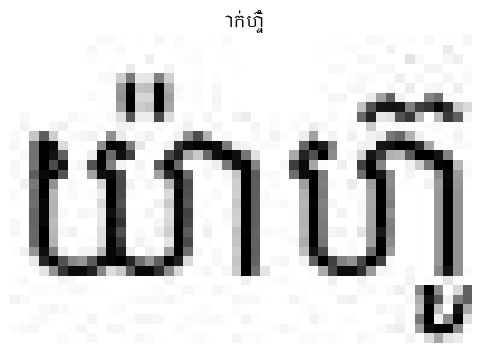

Generated Text: ាក់ហ៊ុំូ


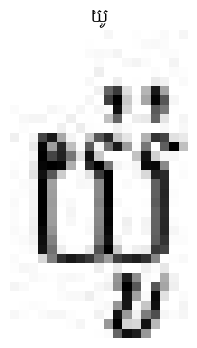

Generated Text: យូូ


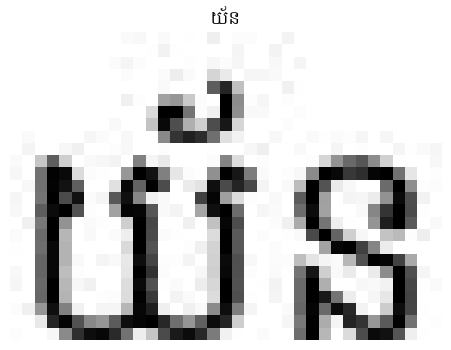

Generated Text: យ័ន


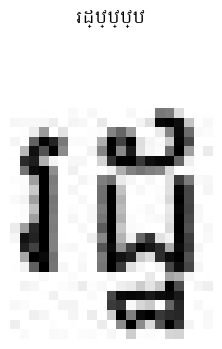

Generated Text: រដ្ឋ្ឋ្ឋ្ឋ


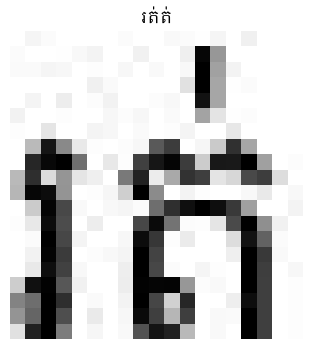

Generated Text: រត់ត់


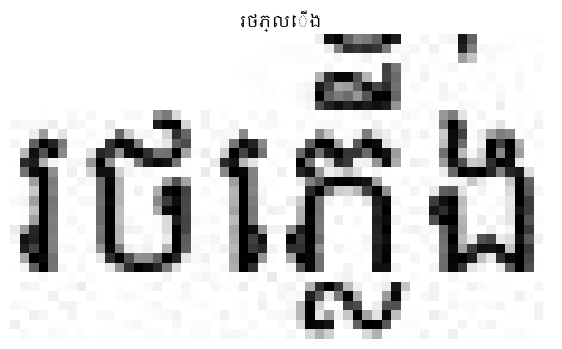

Generated Text: រថភ្លើង


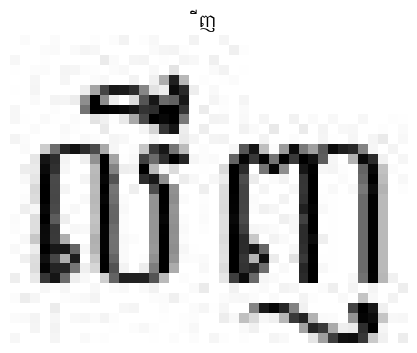

Generated Text: ីញ


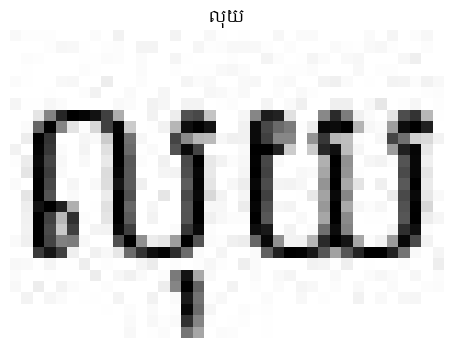

Generated Text: លុយ


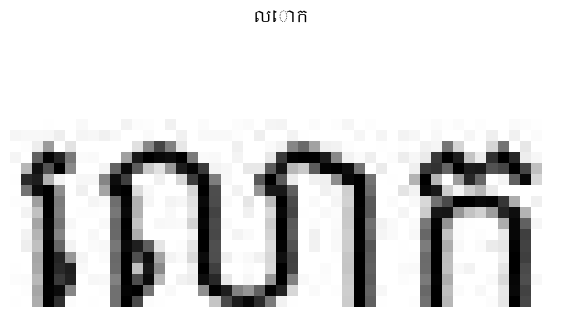

Generated Text: លោក


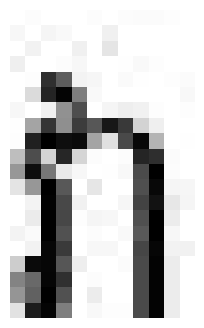

Generated Text: 


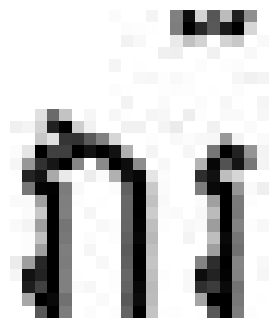

Generated Text: 


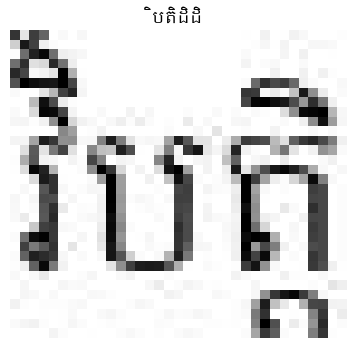

Generated Text: ិបតិិដិដិ


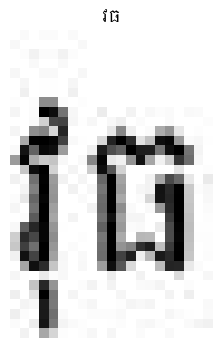

Generated Text: វធ


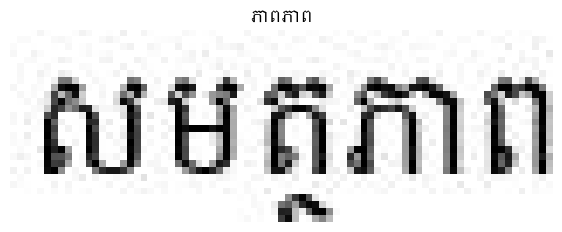

Generated Text: ភាពភាព


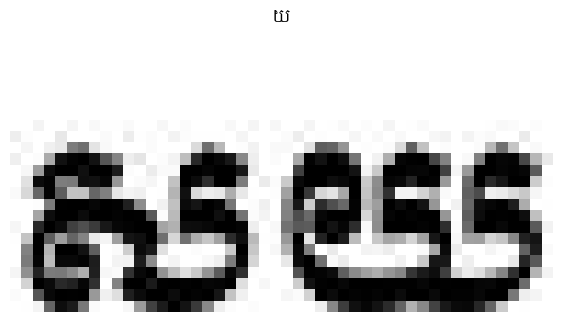

Generated Text: យ


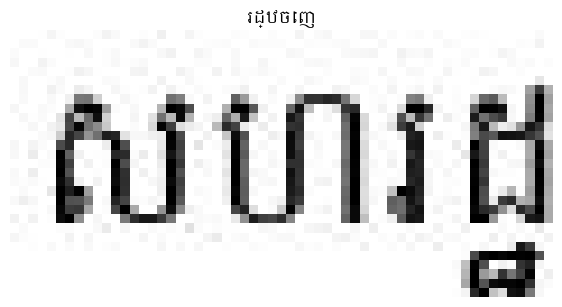

Generated Text: រដ្ឋចេញ


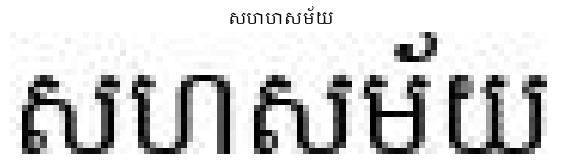

Generated Text: សហហសម័យ


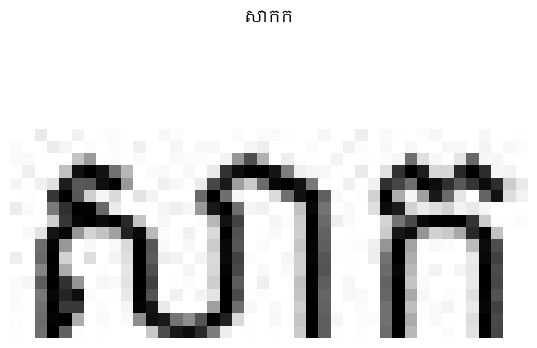

Generated Text: សាកក


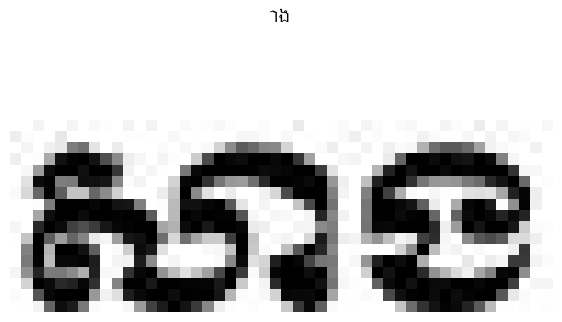

Generated Text: ាង


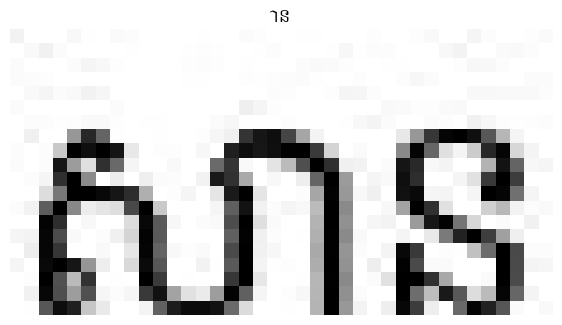

Generated Text: ាន


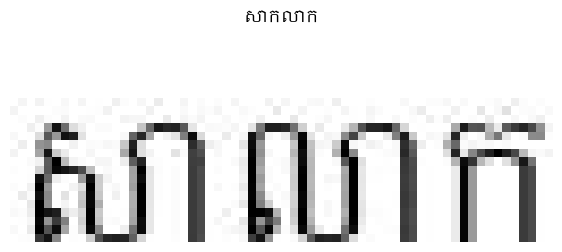

Generated Text: សាកលាក


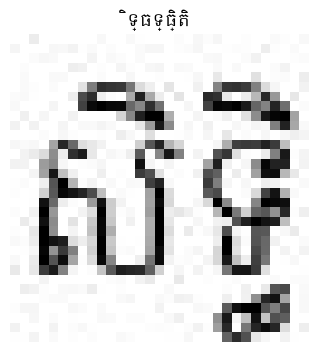

Generated Text: ិទ្ធទ្ធិ្តិ


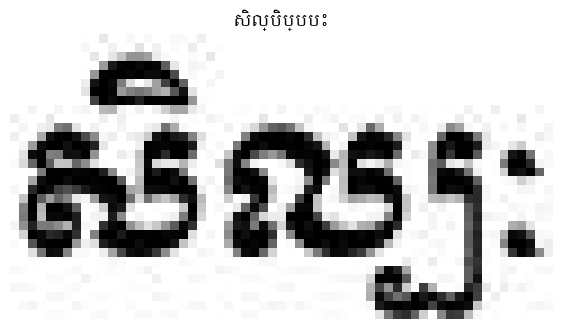

Generated Text: សិល្បិប្បបះ


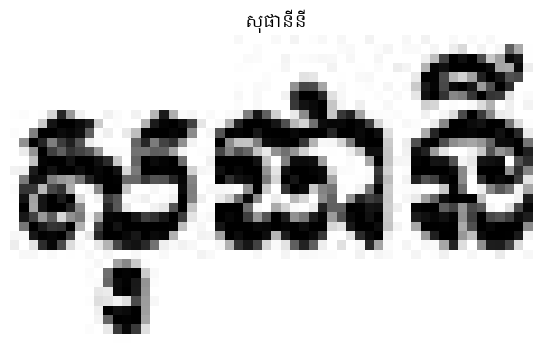

Generated Text: សុផានីនី


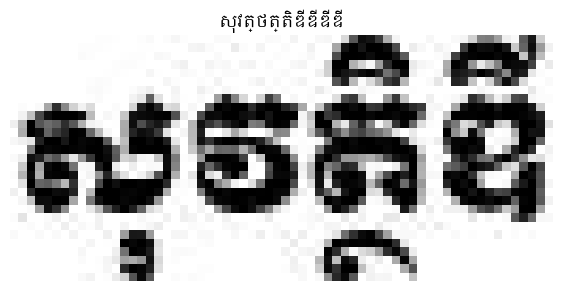

Generated Text: សុវត្ថត្តិិឌីឌីឌីឌី


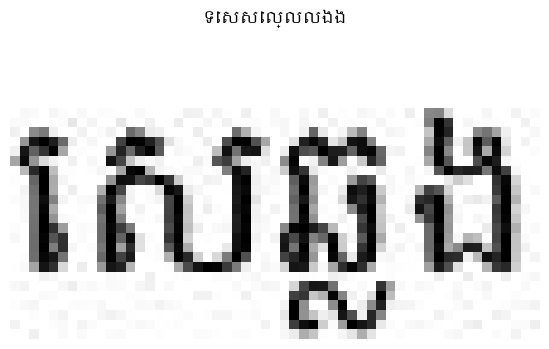

Generated Text: ទេសសេល្លលងង


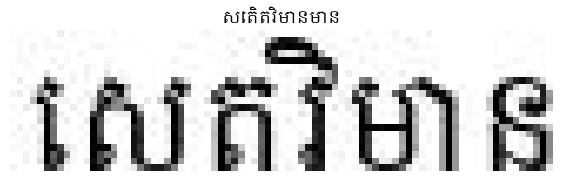

Generated Text: សេតិតវិមានមាន


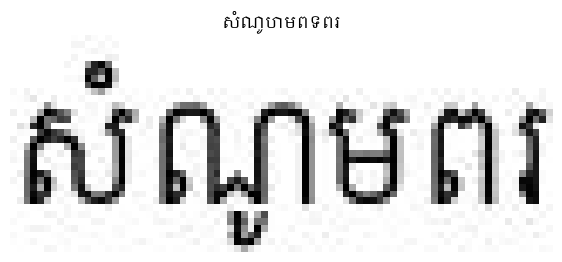

Generated Text: សំណូហមពទពរ


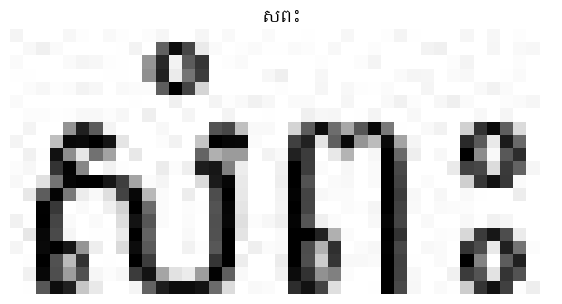

Generated Text: សពះ


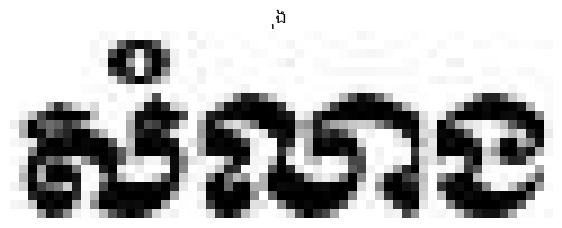

Generated Text: ុង


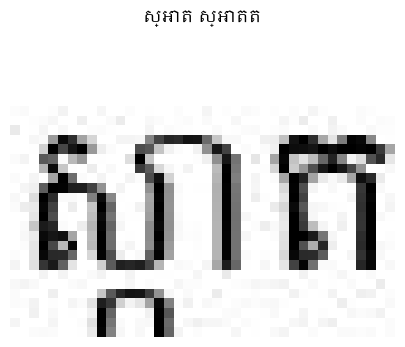

Generated Text: ស្អាត ស្អាតត


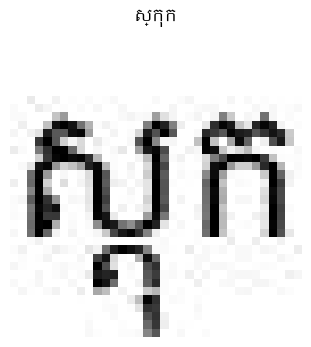

Generated Text: ស្កុក


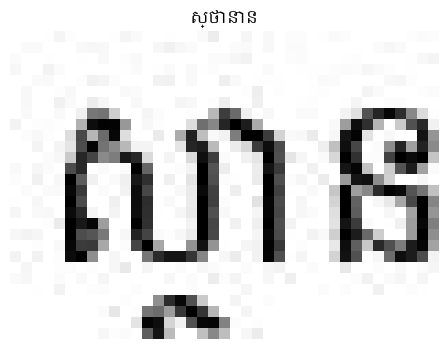

Generated Text: ស្ថានាន


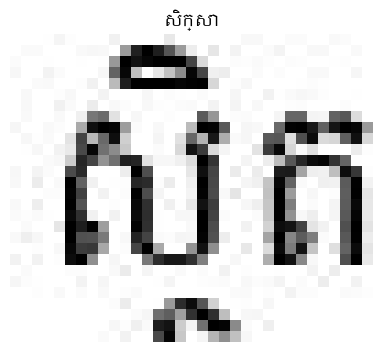

Generated Text: សិក្សា


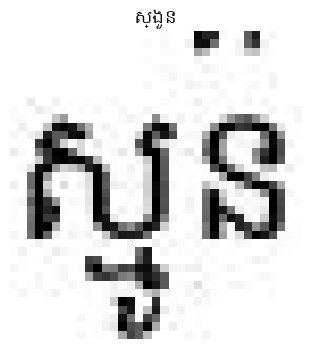

Generated Text: ស្ងួន


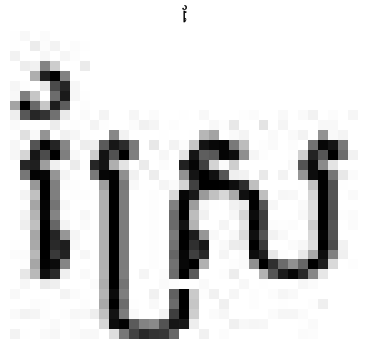

Generated Text: ែ


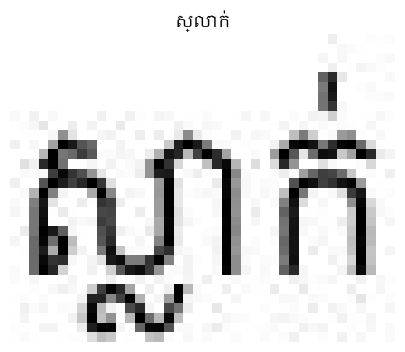

Generated Text: ស្លាក់


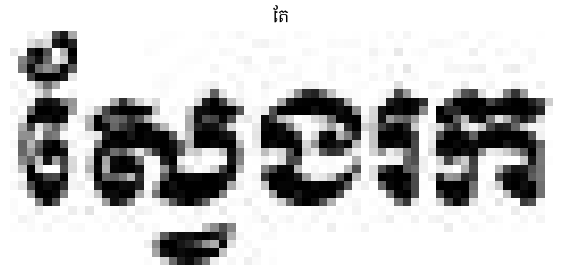

Generated Text: ែត


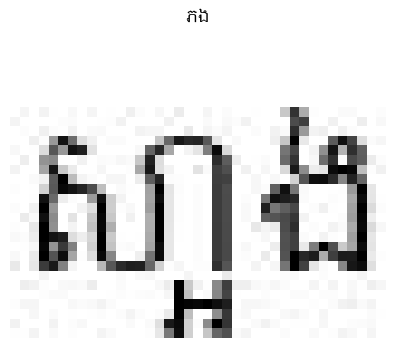

Generated Text: ភង


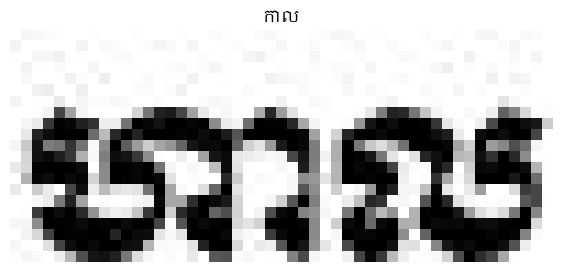

Generated Text: កាល


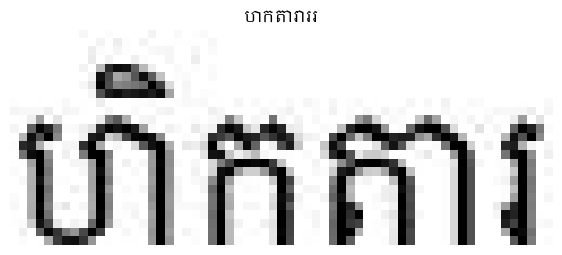

Generated Text: ហកតារាររ


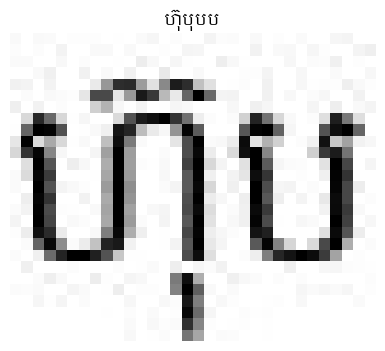

Generated Text: ហ៊ុុបុបប


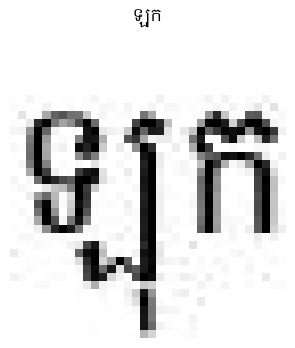

Generated Text: ឡុក


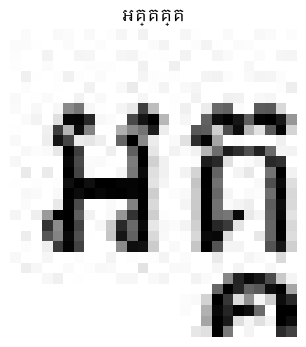

Generated Text: អគ្គគ្គ


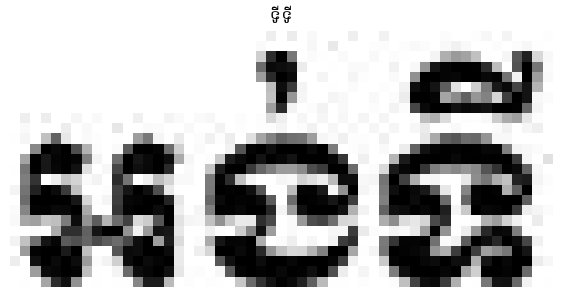

Generated Text: ទីទី


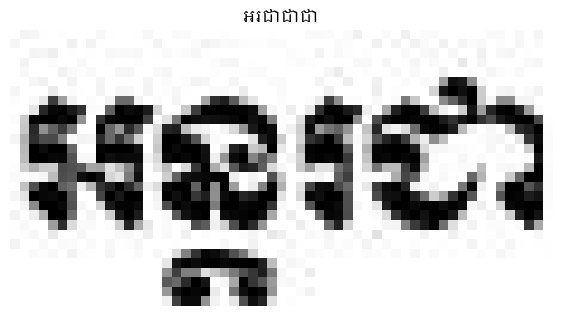

Generated Text: អរជាជាជា


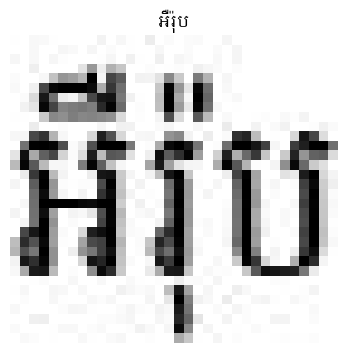

Generated Text: អឺរ៉ុប


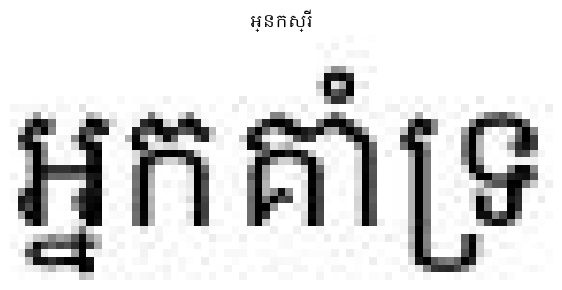

Generated Text: អ្នកស្រី


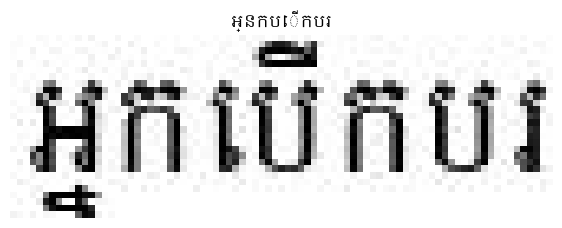

Generated Text: អ្នកបើកបរ


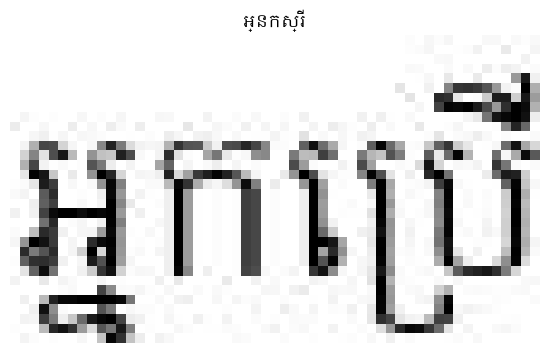

Generated Text: អ្នកស្រី


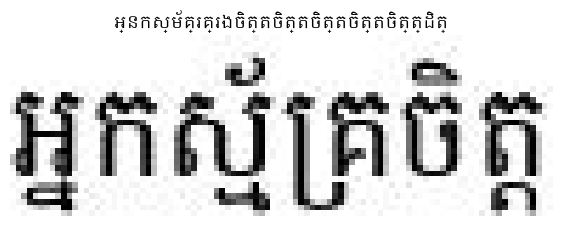

Generated Text: អ្នកស្ម័គ្រគ្រងចិត្តចិត្តចិត្តចិត្តចិត្ត្ដិត្


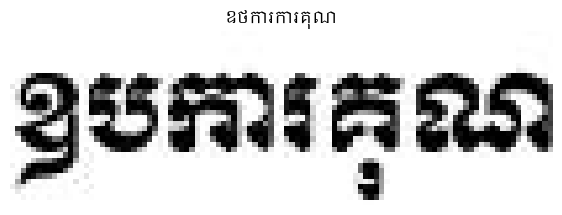

Generated Text: ឧថការការគុណ


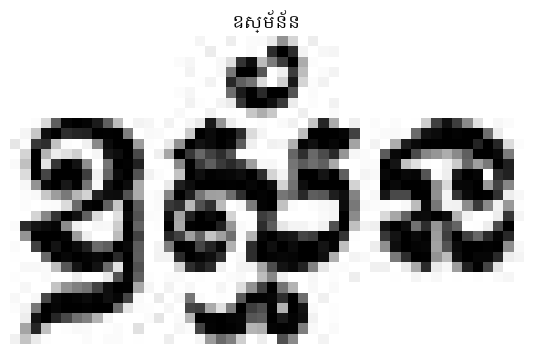

Generated Text: ឧស្ម័័ន័ន


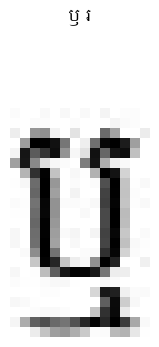

Generated Text: ឫ រ


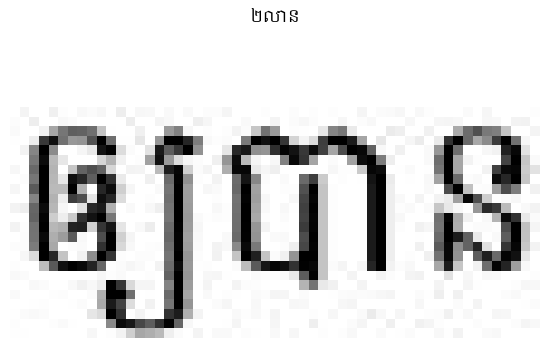

Generated Text: ២លាន


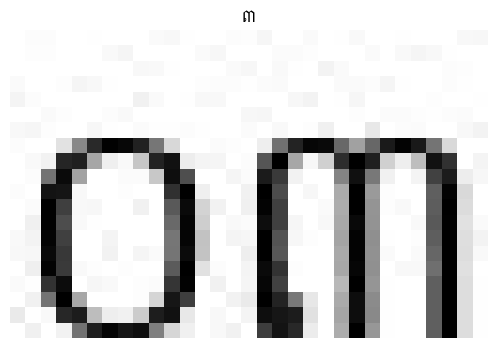

Generated Text: ៣


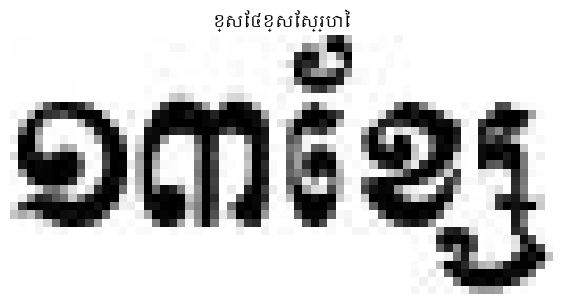

Generated Text: ខ្សែ៤ខ្សែស្រ្ហៃ


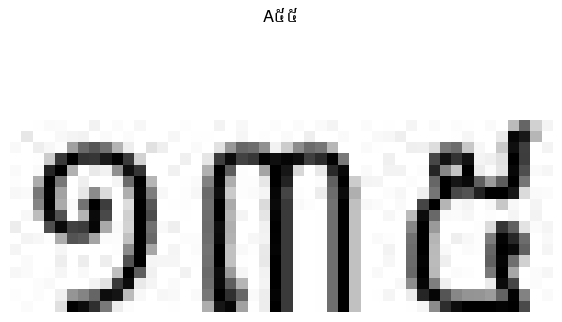

Generated Text: A៥៥


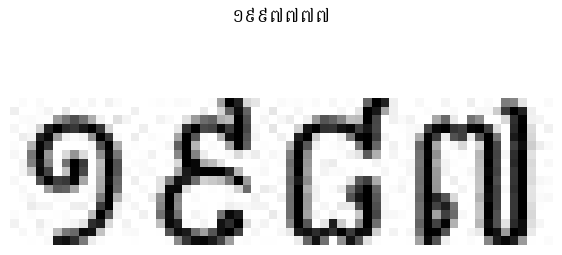

Generated Text: ១៩៩៧៧៧៧


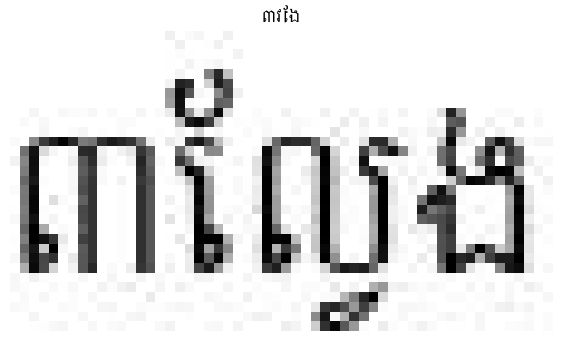

Generated Text: ៣វែង


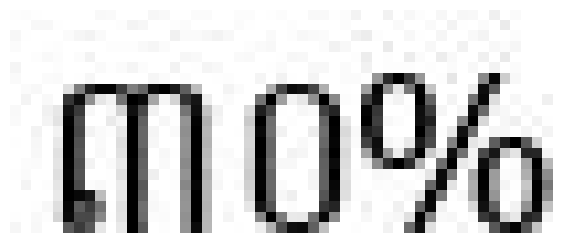

Generated Text: 


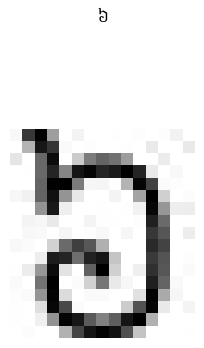

Generated Text: ៦


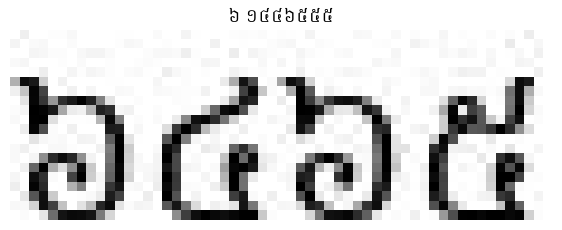

Generated Text: ៦ ១៤៤៦៥៥៥


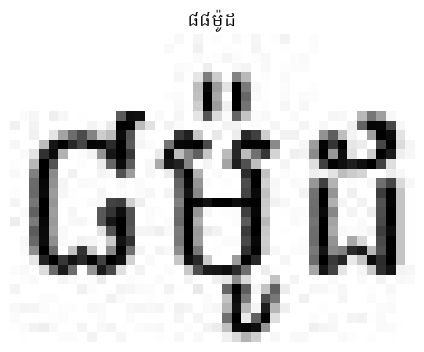

Generated Text: ៨៨ម៉ូូដ


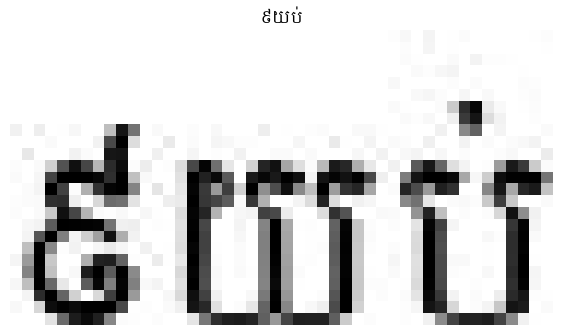

Generated Text: ៩យប់


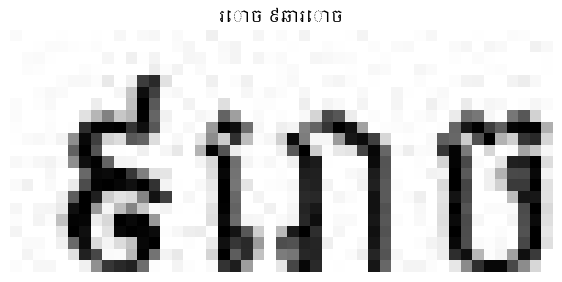

Generated Text: រោច ៩ឆារោច


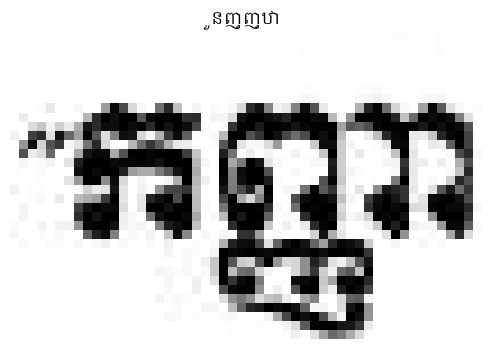

Generated Text: ួនញ្ញ្ឋា


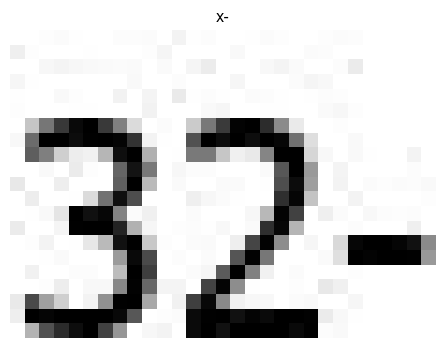

Generated Text: x-


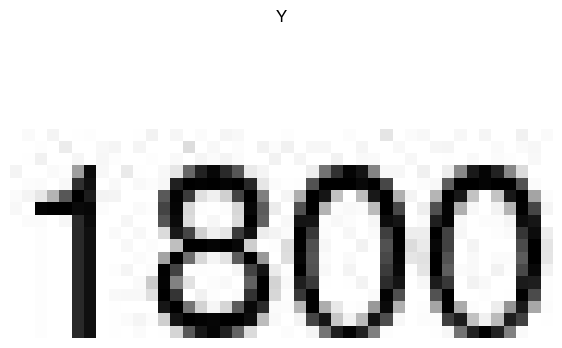

Generated Text: Y


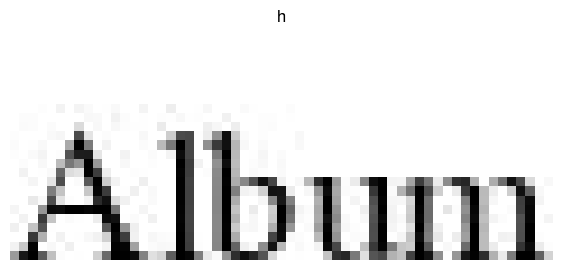

Generated Text: h


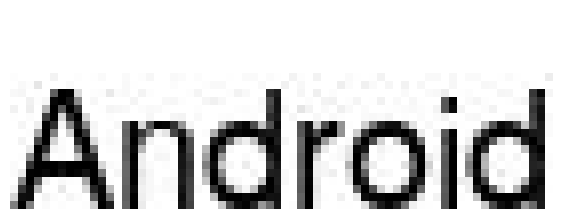

Generated Text: 


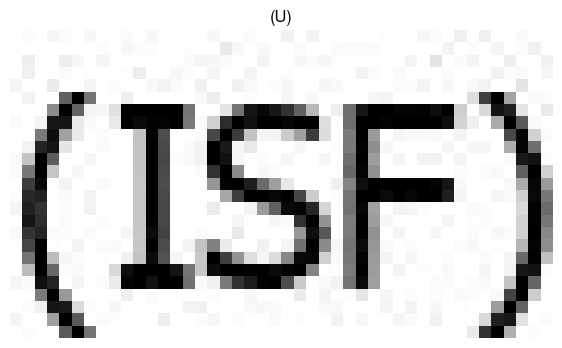

Generated Text: (U)


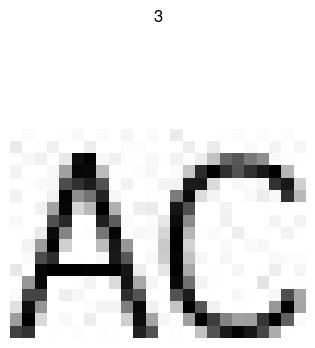

Generated Text: 3


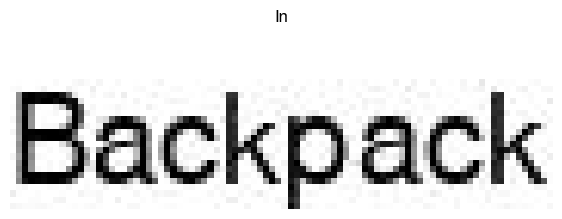

Generated Text: In


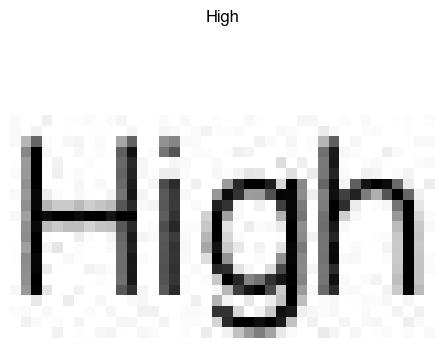

Generated Text: High


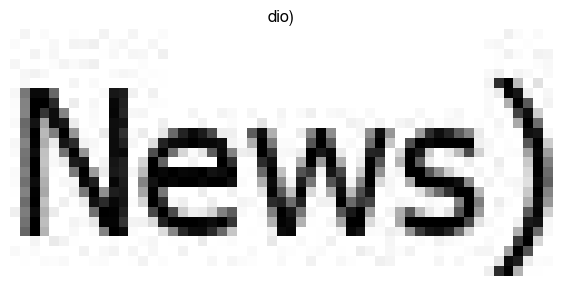

Generated Text: dio)


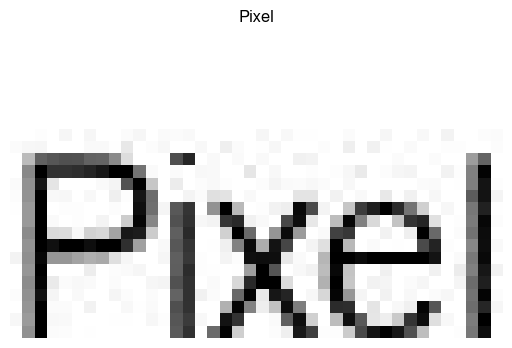

Generated Text: Pixel


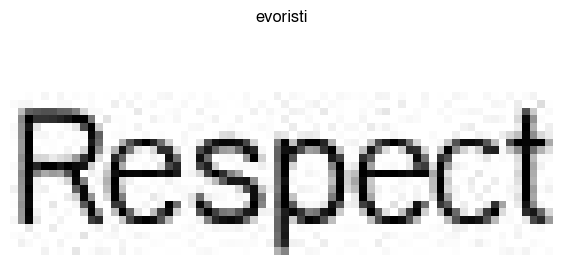

Generated Text: evoristi


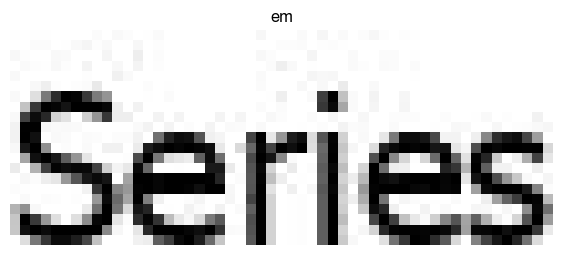

Generated Text: em


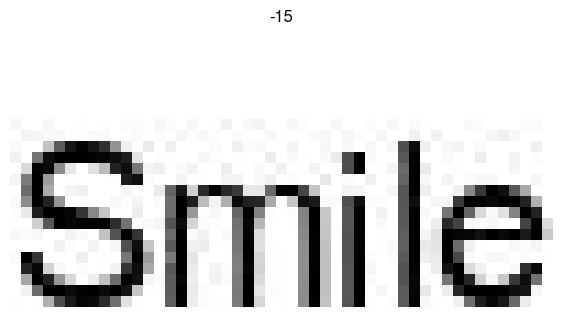

Generated Text: -15


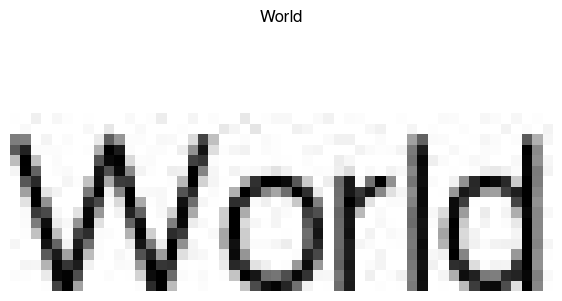

Generated Text: World


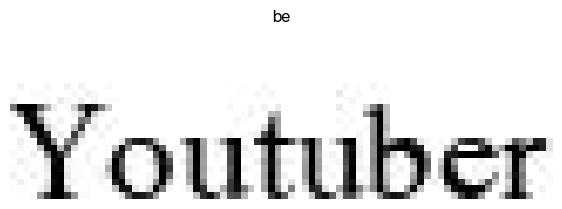

Generated Text: be


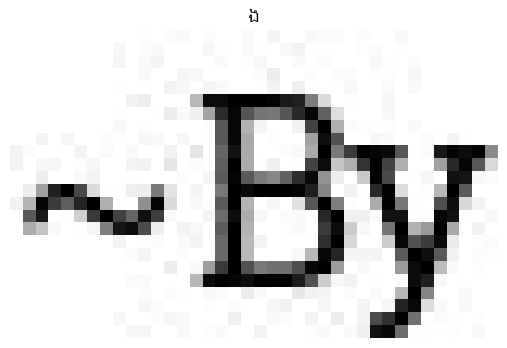

Generated Text: ង


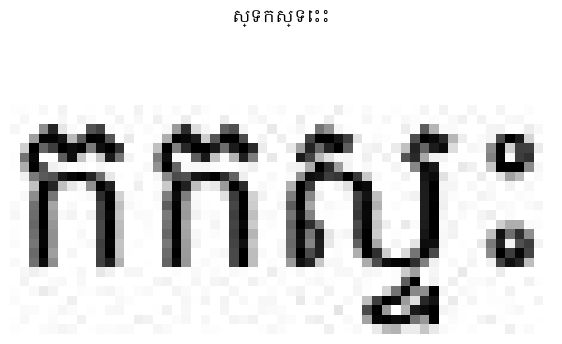

Generated Text: ស្ទកស្ទេះះ


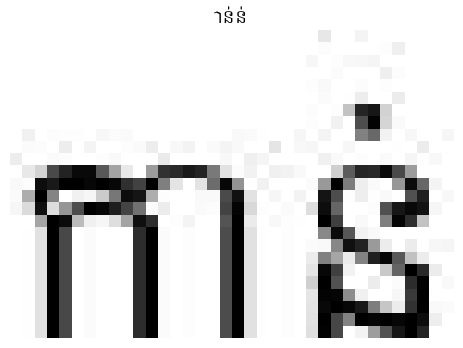

Generated Text: ាន់ន់


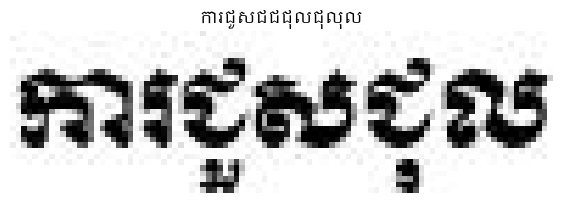

Generated Text: ការជួសជជជុលជុលុល


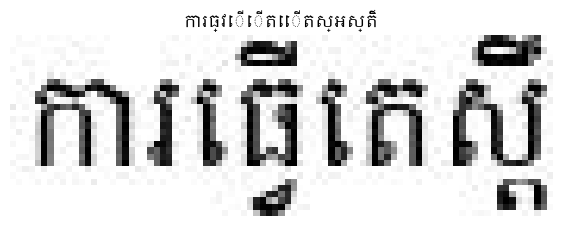

Generated Text: ការធ្វើើតេើតស្អស្តិ៍៍៍៍៍៍៍៍


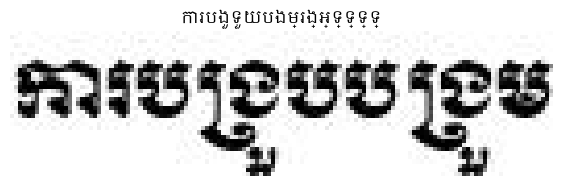

Generated Text: ការបងួទួយបងម្រង្អ្ទ្ទ្ទ្ទ្


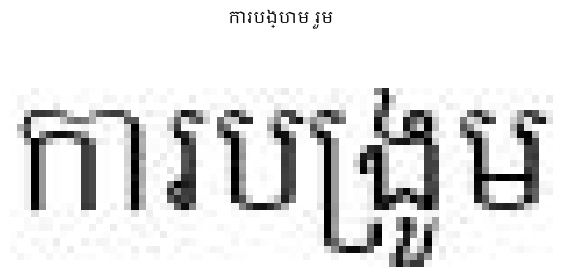

Generated Text: ការបង្ហម រួម


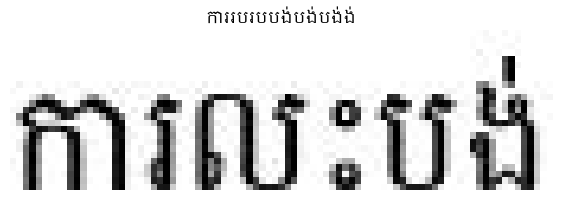

Generated Text: ការរបរបបង់បង់បង់ង់


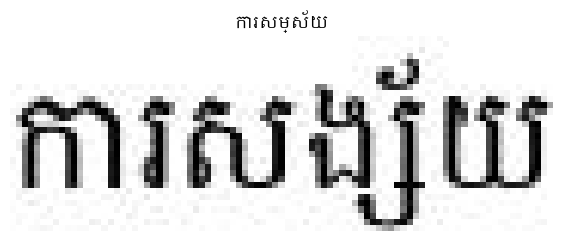

Generated Text: ការសម្ស័យ


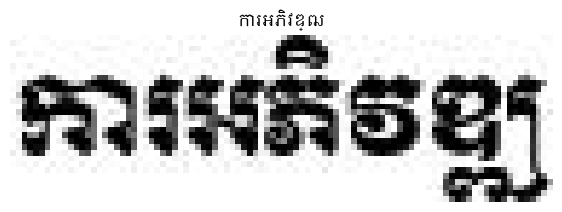

Generated Text: ការអភិវឌ្ឍ


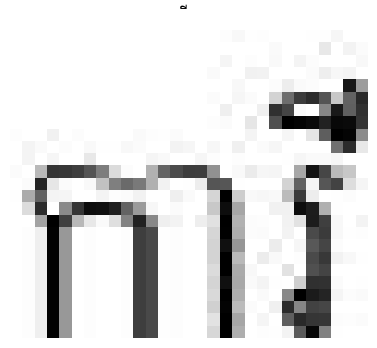

Generated Text: ីី


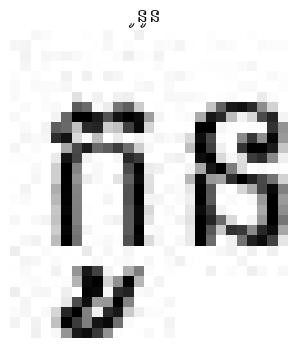

Generated Text: ូនូន


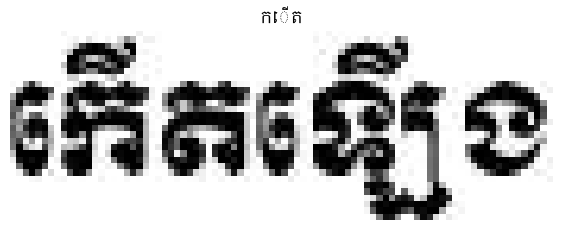

Generated Text: កើត


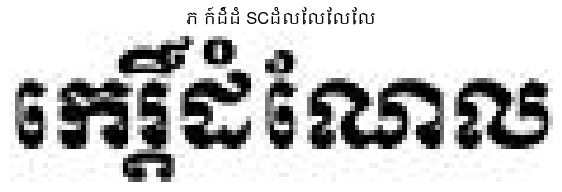

Generated Text: ភ ក៍ដំ៍ដំ SCដំលែលែលែល


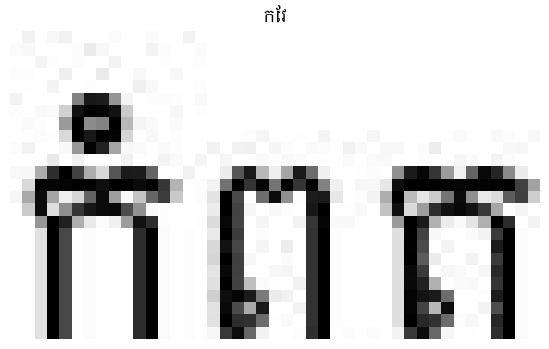

Generated Text: កែវ


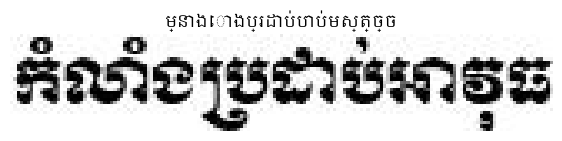

Generated Text: ម្នាងោងប្រដាប់បាប់មស្ត្ច្ច


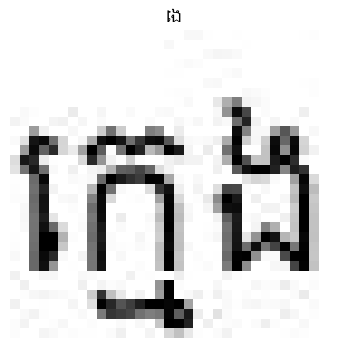

Generated Text: េង


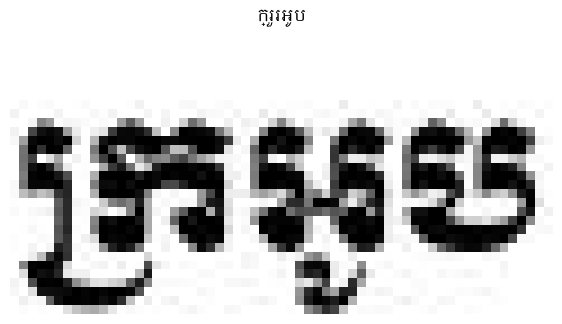

Generated Text: ក្រួរអូប


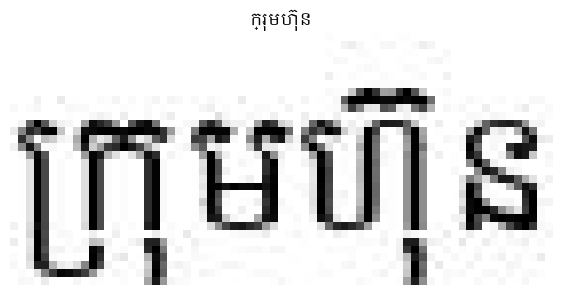

Generated Text: ក្រុមហ៊ុន


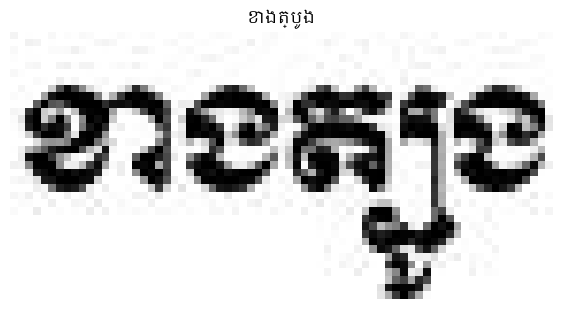

Generated Text: ខាងត្បូង


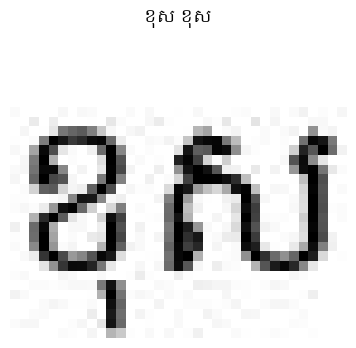

Generated Text: ខុស ខុស


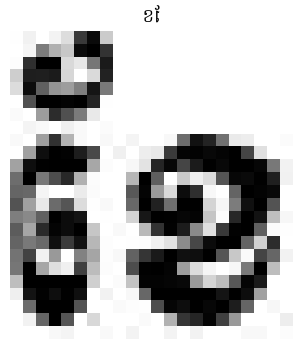

Generated Text: ខែ


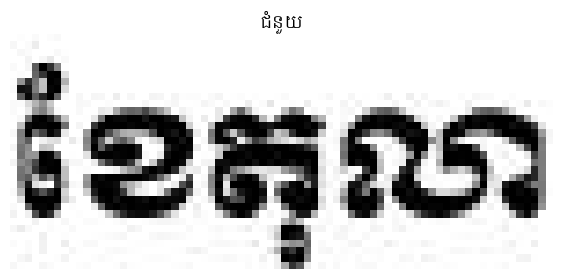

Generated Text: ជំនួយ


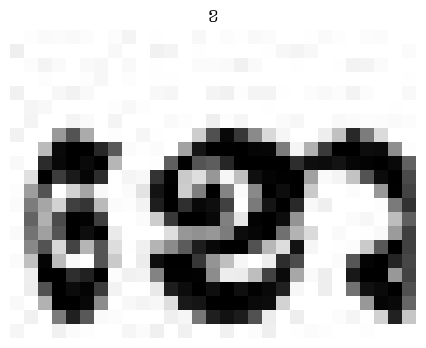

Generated Text: ខ


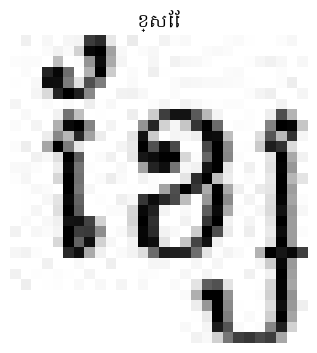

Generated Text: ខ្សែែ


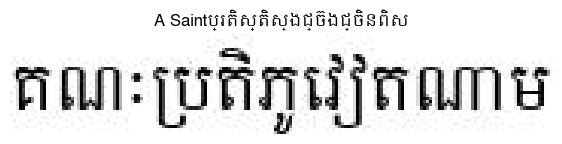

Generated Text: A Saintប្រតិស្តិស្ងជ្ច៊ងជ្ចិនពិស


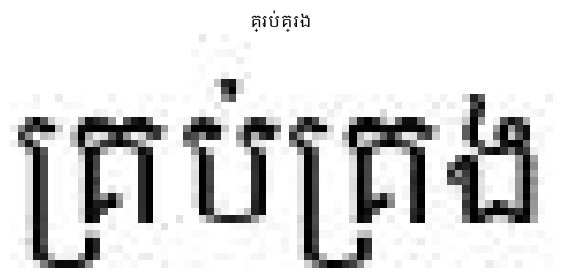

Generated Text: គ្រប់គ្រង


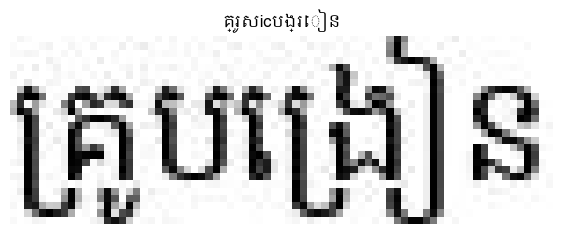

Generated Text: គ្រូូសicបង្រៀន


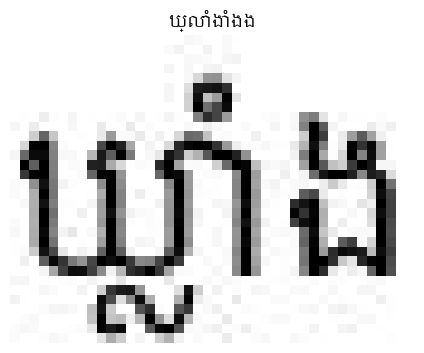

Generated Text: ឃ្លាំងាំងង


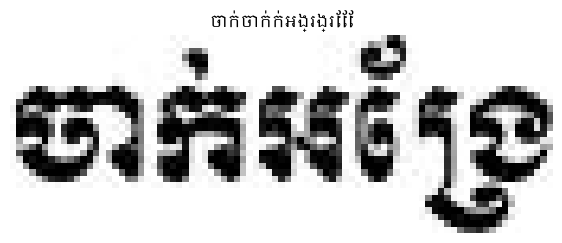

Generated Text: ចាក់ចាក់ក់អង្រង្រែែែ


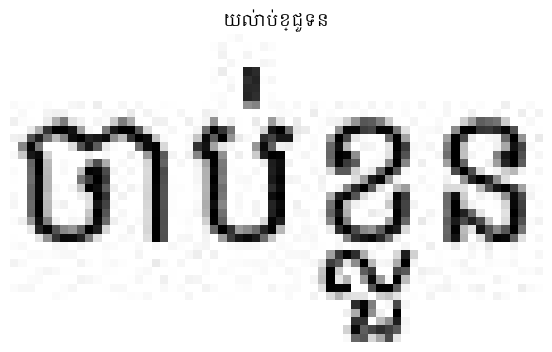

Generated Text: យល់ាប់ខ្ជួទន


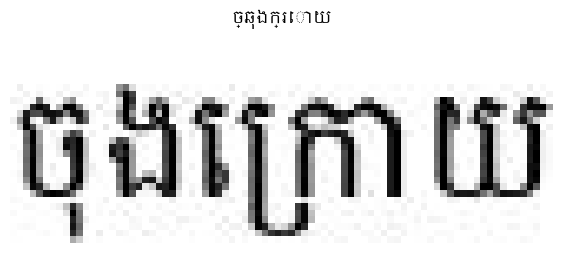

Generated Text: ច្ឆុងក្រោយ


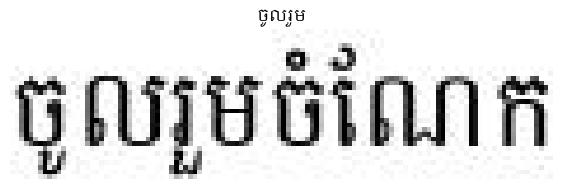

Generated Text: ចូលរួម


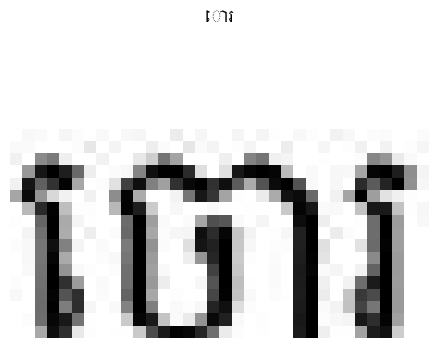

Generated Text: ោរ


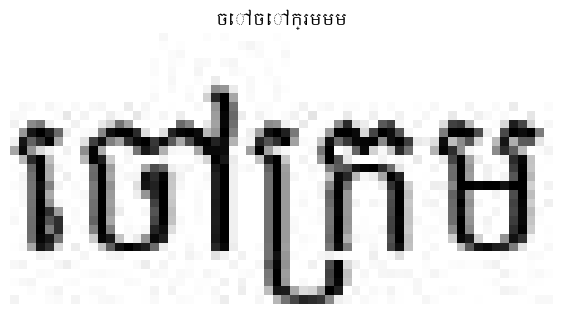

Generated Text: ចៅចៅក្រមមម


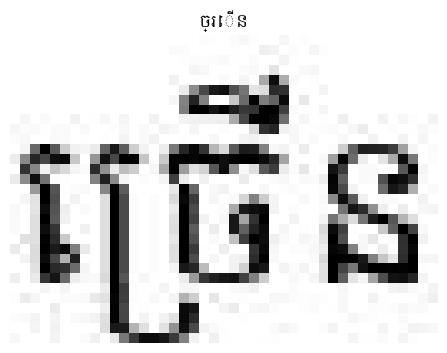

Generated Text: ច្រើន


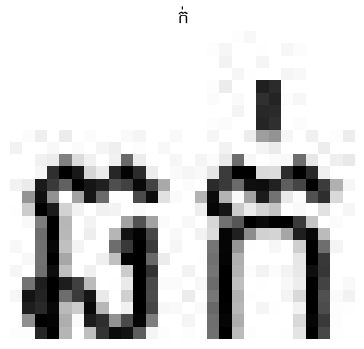

Generated Text: ក់


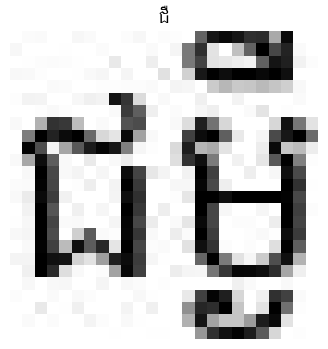

Generated Text: ជឺ


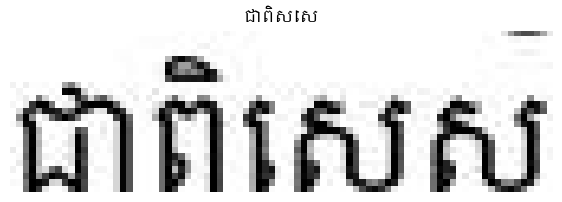

Generated Text: ជាពិសេស


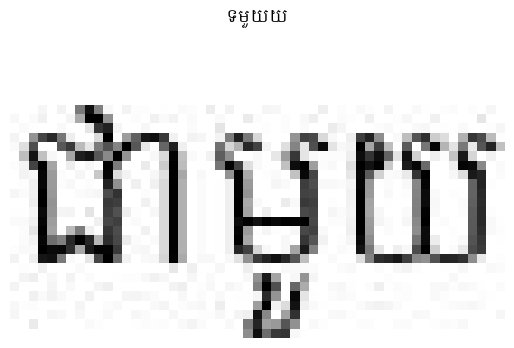

Generated Text: ទមួយយ


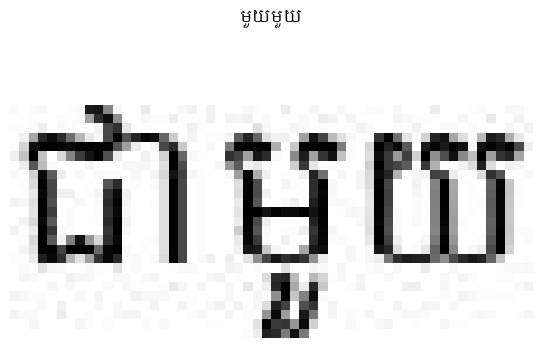

Generated Text: មួយមួយ


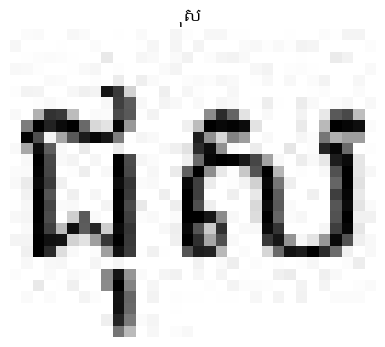

Generated Text: ុស


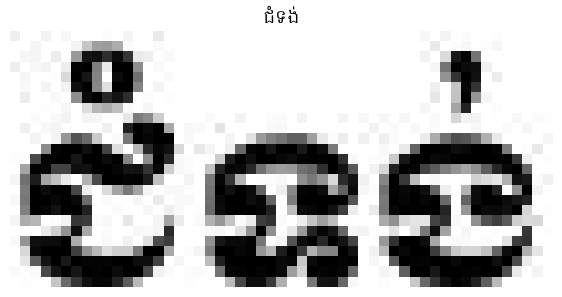

Generated Text: ជំំទង់


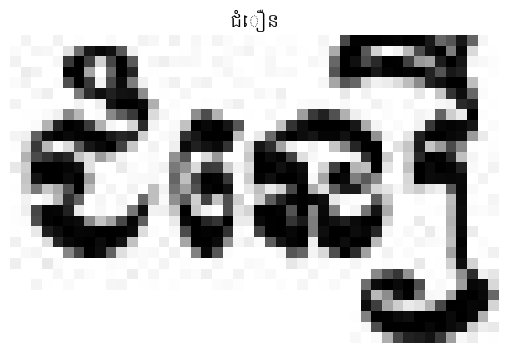

Generated Text: ជំឿន


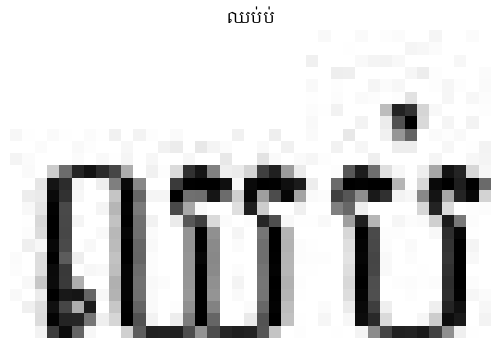

Generated Text: ឈប់ប់


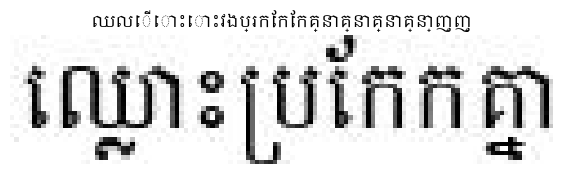

Generated Text: ឈលើោះោះវងប្រកែកែកគ្នាគ្នាគ្នាគ្នា្ញ្ញ្


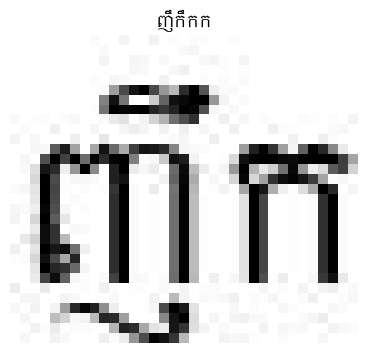

Generated Text: ញឹកឹកក


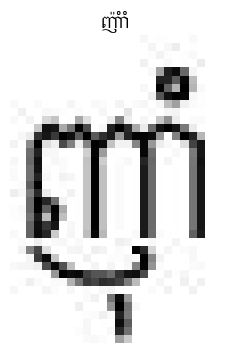

Generated Text: ញ៉ាំាំ


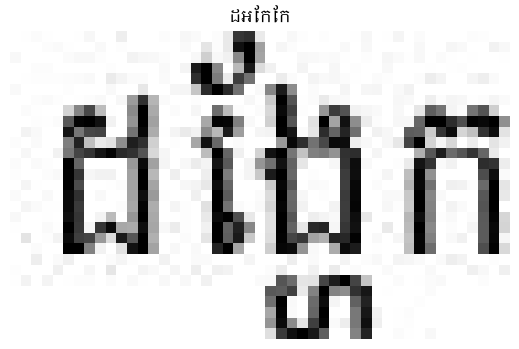

Generated Text: ដអែកែក


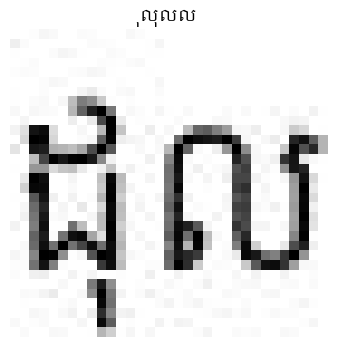

Generated Text: ុលុលល


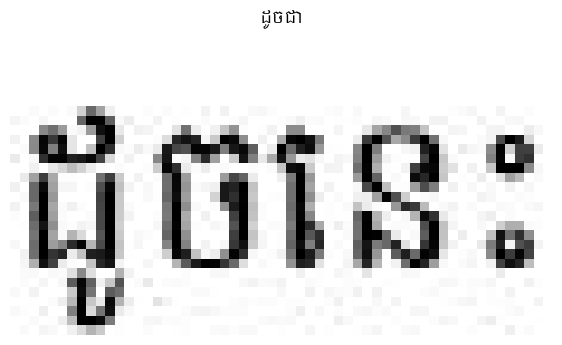

Generated Text: ដូចជា


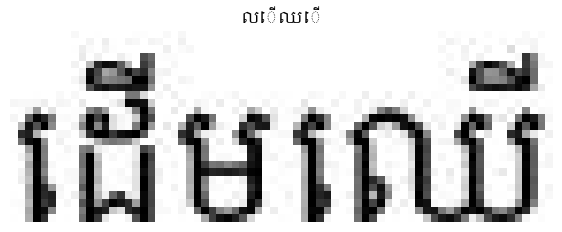

Generated Text: លើឈើ


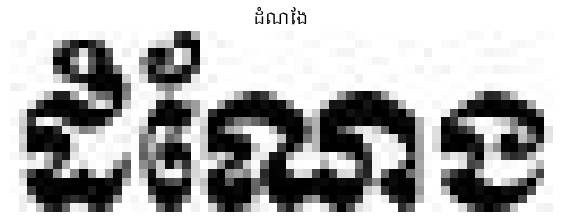

Generated Text: ដំណែង


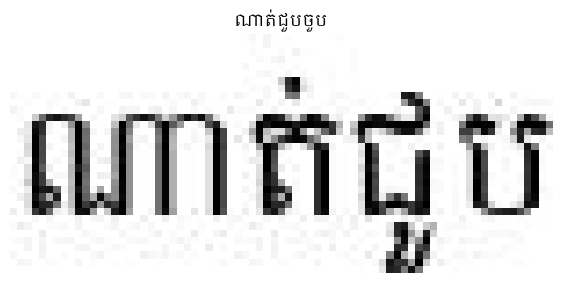

Generated Text: ណាត់ជួបចួប


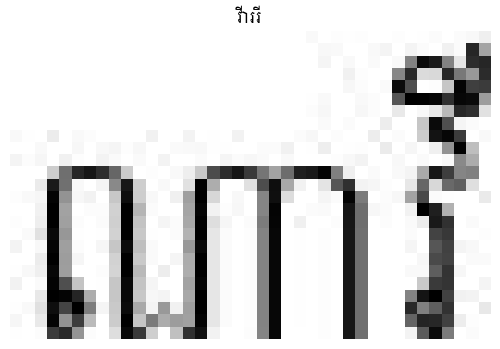

Generated Text: វីាររី


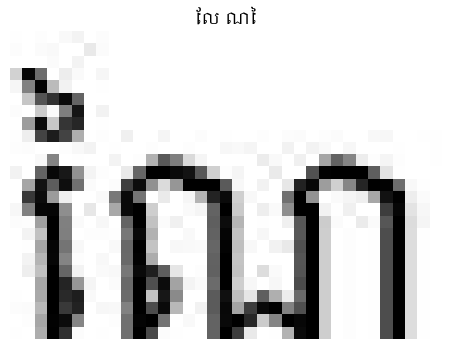

Generated Text: ែល ណៃ


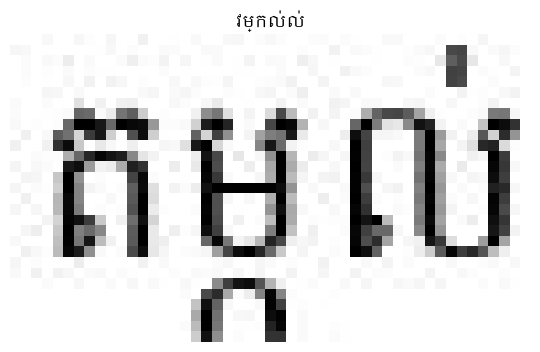

Generated Text: វម្កល់ល់


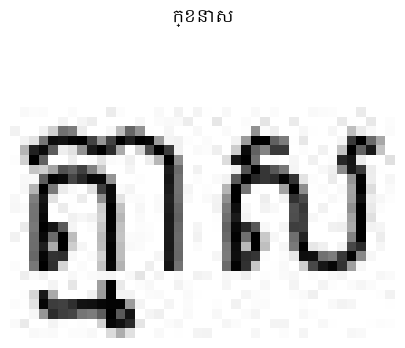

Generated Text: ក្ខនាស


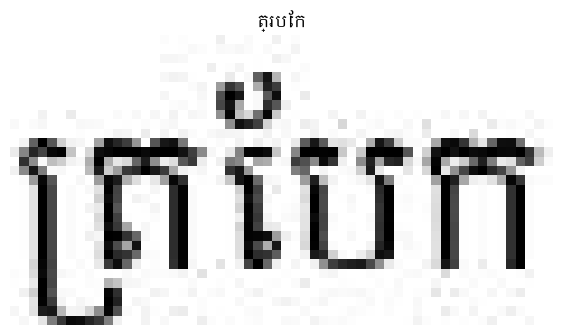

Generated Text: ត្របែក


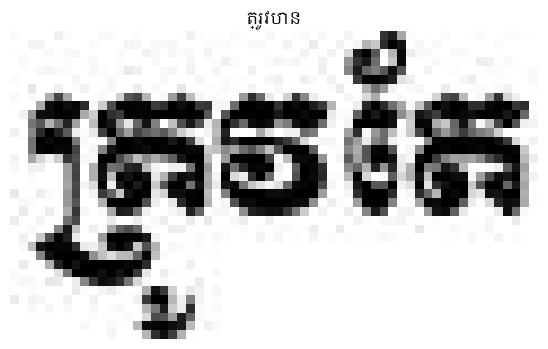

Generated Text: ត្រូវបាន


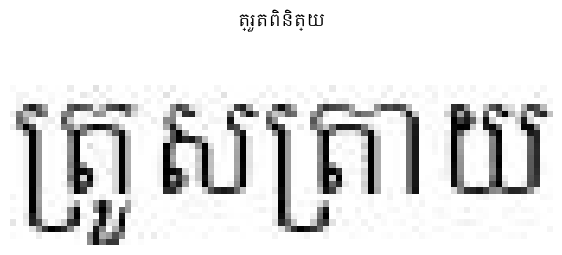

Generated Text: ត្រួតពិនិត្យ


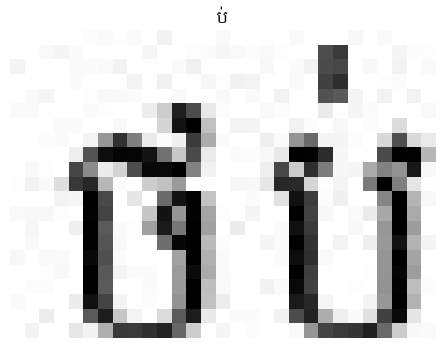

Generated Text: ប់


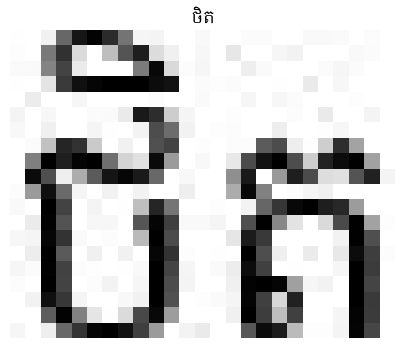

Generated Text: ថិត


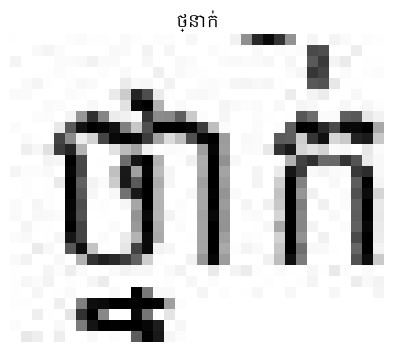

Generated Text: ថ្នាក់


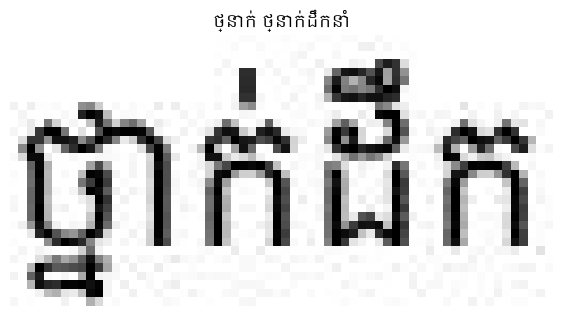

Generated Text: ថ្នាក់ ថ្នាក់ដឹកនាំ


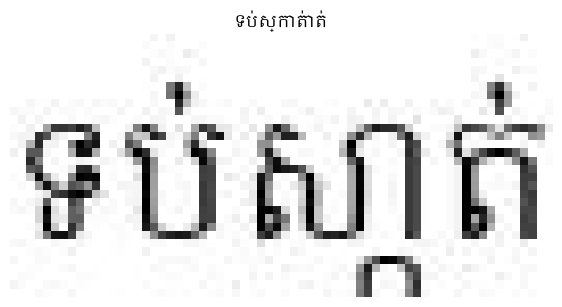

Generated Text: ទប់ស្កាត់ាត់


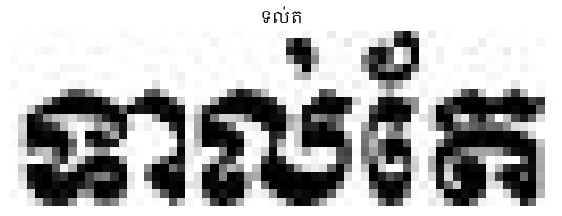

Generated Text: ទល់ត


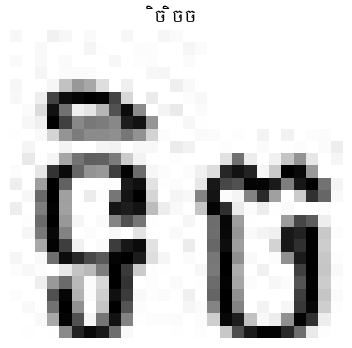

Generated Text: ិច ិចច


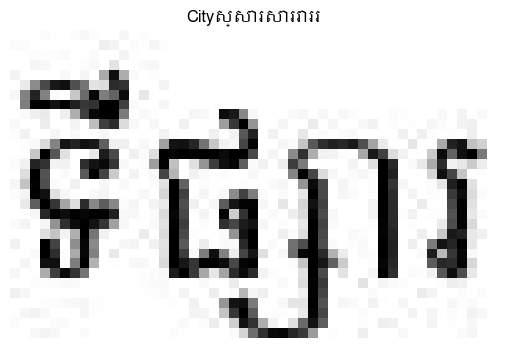

Generated Text: Cityស្សារសាររាររ


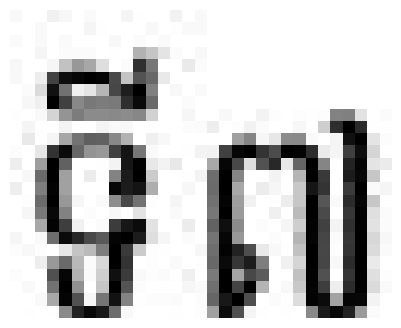

Generated Text: 


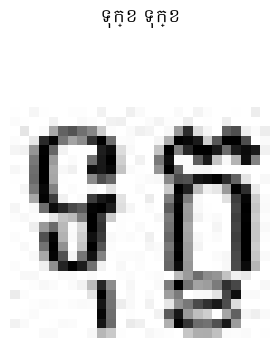

Generated Text: ទុក្ខ ទុក្ខ


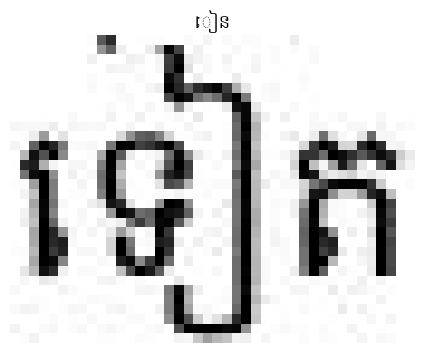

Generated Text: ៀន


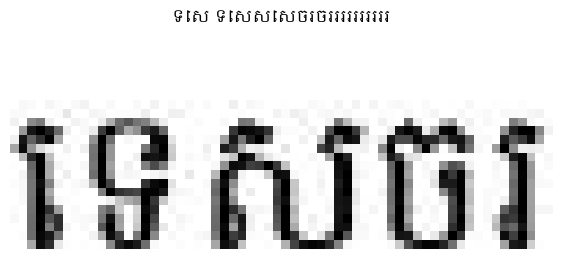

Generated Text: ទេស ទេសសេសចរចររររររររររ


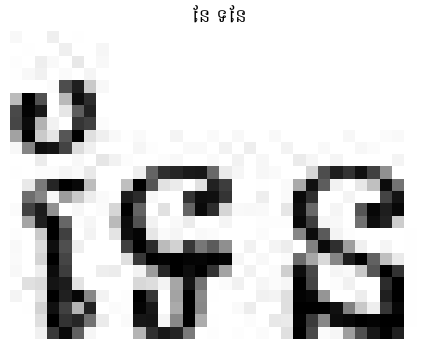

Generated Text: ែន ទែន


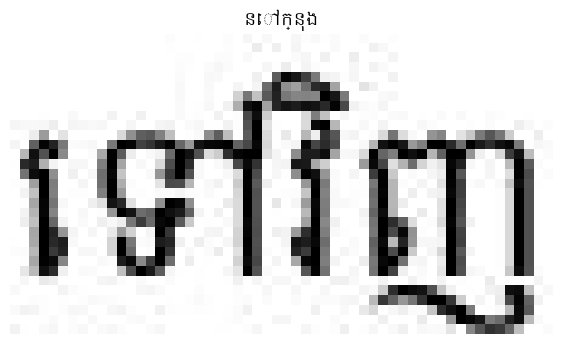

Generated Text: នៅក្នុង


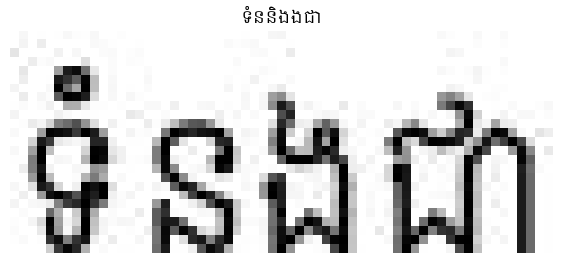

Generated Text: ទំននិងងជា


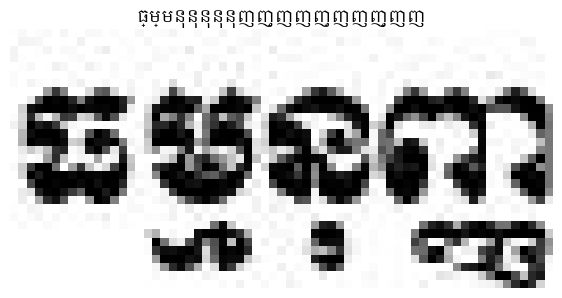

Generated Text: ធ្ម្មនុនុនុនុនុញញ្ញញញ្ញញញ្ញញ


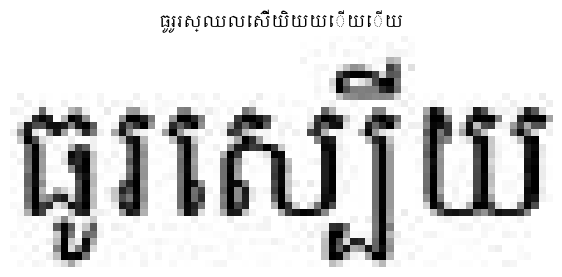

Generated Text: ធូរូរស្ឈលេស៊ីយិយយើយើយ


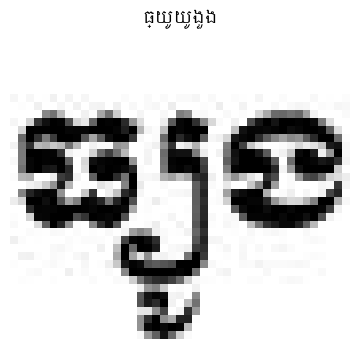

Generated Text: ធ្យូយូងួង


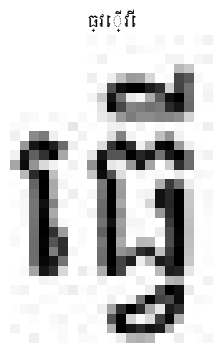

Generated Text: ធ្វើ្វេី


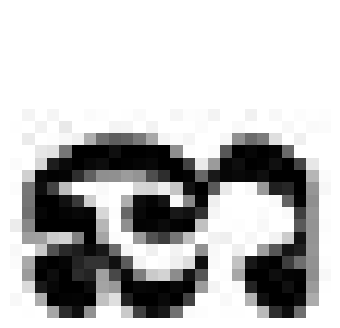

Generated Text: 


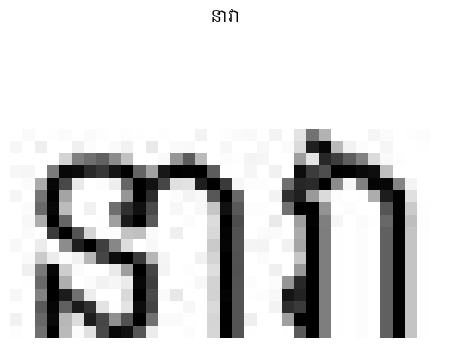

Generated Text: នាវា


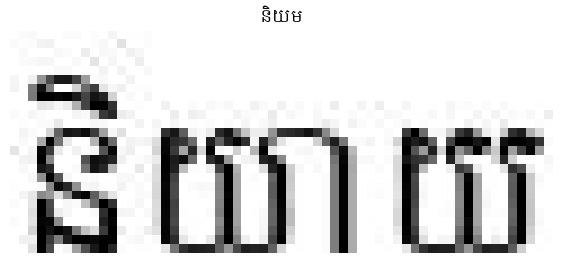

Generated Text: និយម


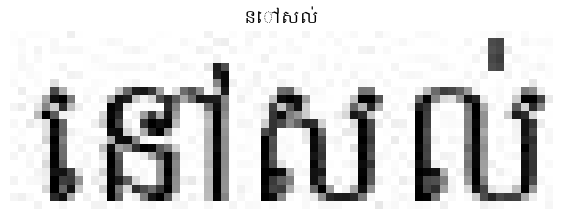

Generated Text: នៅសល់


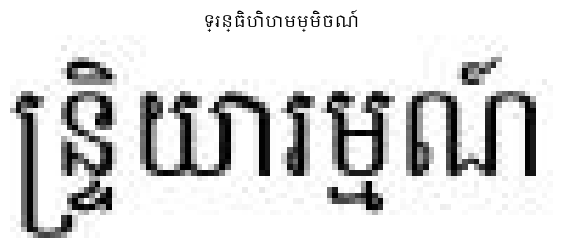

Generated Text: ទ្រន្ធិហិហមម្មិចណ៍


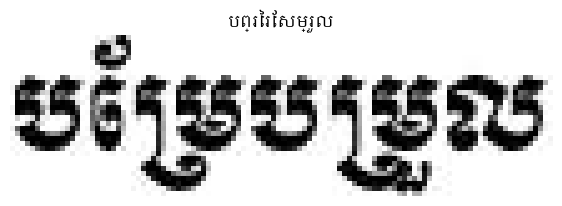

Generated Text: បព្រៃរែសម្រួល


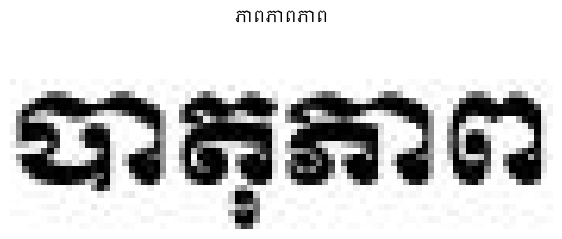

Generated Text: ភាពភាពភាព


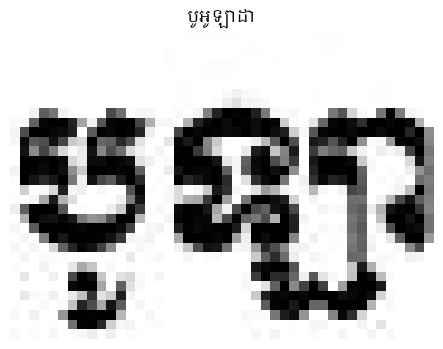

Generated Text: បូអូឡាដា


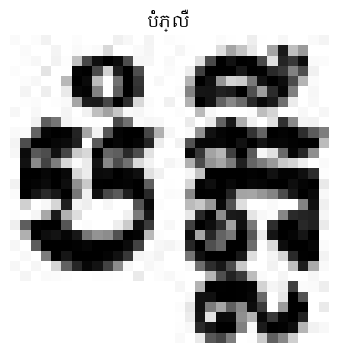

Generated Text: បំ៉ភ្លឺឺ


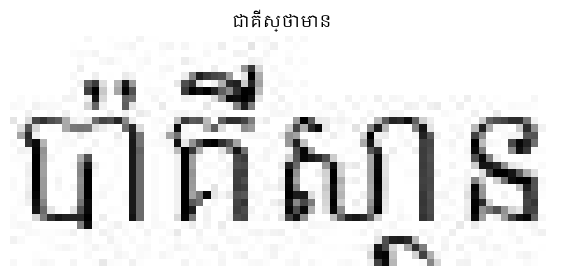

Generated Text: ជាគីីស្ថាមាន


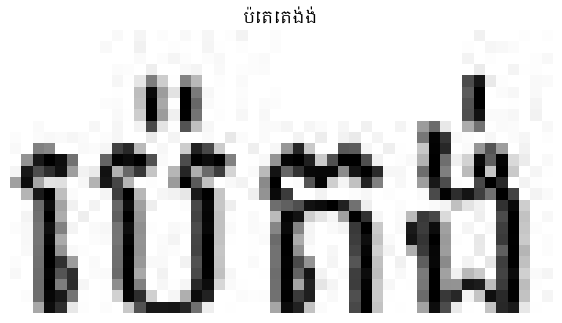

Generated Text: ប៉េតេតង់ង់


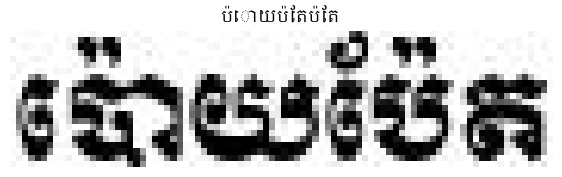

Generated Text: ប៉ោយប៉ែតប៉ែត


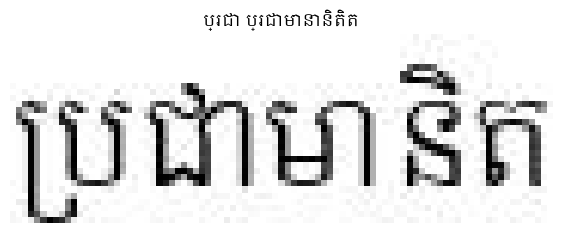

Generated Text: ប្រជា ប្រជាមានានិតិត


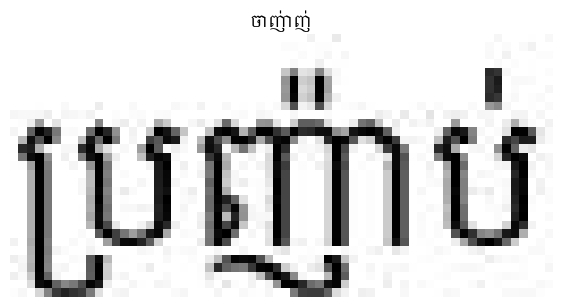

Generated Text: ចាញ់ាញ់


In [50]:
eval_new_data(
    data_path=os.path.join(DatasetConfig.DATA_ROOT, 'data_test', '*'),
    num_samples=300
)